In [1]:
import hashlib
import csv
from pathlib import Path
from collections import defaultdict

# ==========================================================
# KONFIGURASI PATH DATASET ORIGINAL
# ==========================================================
ORIGINAL_DIR = Path(r"D:\TUGAS AKHIR\data_final\images")
OUTPUT_DIR = Path(r"D:\TUGAS AKHIR\hasil_md5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["benign", "malignant"]
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}


def get_md5(file_path, chunk_size=1024 * 1024):
    """Menghasilkan hash MD5 dari isi file citra."""
    md5_hash = hashlib.md5()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            md5_hash.update(chunk)

    return md5_hash.hexdigest()


def get_image_files(dataset_dir):
    """Mengambil seluruh file citra benign dan malignant."""
    image_files = []

    for label in CLASSES:
        class_dir = dataset_dir / label

        if not class_dir.exists():
            print(f"⚠️ Folder tidak ditemukan: {class_dir}")
            continue

        for file_path in class_dir.iterdir():
            if file_path.is_file() and file_path.suffix.lower() in VALID_EXTENSIONS:
                image_files.append({
                    "filepath": file_path,
                    "label": label
                })

    return image_files


def check_duplicates():
    print("=" * 65)
    print("PENGECEKAN DUPLIKASI DATASET ORIGINAL DENGAN MD5")
    print("=" * 65)

    image_files = get_image_files(ORIGINAL_DIR)

    print(f"Total citra ditemukan: {len(image_files):,}")
    print("Memproses hash MD5...\n")

    hash_map = defaultdict(list)
    hash_records = []
    errors = []

    for index, item in enumerate(image_files, start=1):
        file_path = item["filepath"]
        label = item["label"]

        try:
            md5_value = get_md5(file_path)

            hash_map[md5_value].append({
                "filepath": str(file_path),
                "label": label
            })

            hash_records.append({
                "filepath": str(file_path),
                "label": label,
                "md5": md5_value
            })

        except Exception as e:
            errors.append({
                "filepath": str(file_path),
                "error": str(e)
            })

        if index % 500 == 0 or index == len(image_files):
            print(f"Progress: {index:,}/{len(image_files):,} gambar")

    duplicates = {
        md5: files
        for md5, files in hash_map.items()
        if len(files) > 1
    }

    total_files = len(hash_records)
    unique_hashes = len(hash_map)
    duplicate_groups = len(duplicates)
    duplicate_files = sum(len(files) for files in duplicates.values())
    excess_duplicates = total_files - unique_hashes

    print("\n" + "-" * 65)
    print("HASIL PENGECEKAN")
    print("-" * 65)
    print(f"Total file diperiksa        : {total_files:,}")
    print(f"Jumlah hash unik            : {unique_hashes:,}")
    print(f"Kelompok duplikasi          : {duplicate_groups:,}")
    print(f"File terlibat duplikasi     : {duplicate_files:,}")
    print(f"Jumlah duplikat tambahan    : {excess_duplicates:,}")
    print(f"File gagal dibaca           : {len(errors):,}")

    if duplicate_groups == 0:
        print("\n✅ Tidak ditemukan duplikasi sempurna.")
        print("✅ Seluruh citra memiliki nilai hash MD5 yang unik.")
    else:
        print("\n⚠️ Ditemukan file dengan hash MD5 yang sama.")

    # Simpan hash seluruh file
    hash_csv = OUTPUT_DIR / "hash_md5_dataset_original.csv"

    with open(hash_csv, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=["filepath", "label", "md5"])
        writer.writeheader()
        writer.writerows(hash_records)

    # Simpan detail duplikasi
    duplicate_csv = OUTPUT_DIR / "duplikasi_md5_dataset_original.csv"

    with open(duplicate_csv, "w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["md5", "jumlah_file", "label", "filepath"])

        for md5_value, files in duplicates.items():
            for item in files:
                writer.writerow([
                    md5_value,
                    len(files),
                    item["label"],
                    item["filepath"]
                ])

    # Simpan error jika ada
    if errors:
        error_csv = OUTPUT_DIR / "error_md5_dataset_original.csv"

        with open(error_csv, "w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=["filepath", "error"])
            writer.writeheader()
            writer.writerows(errors)

    print(f"\n📁 Hasil disimpan di: {OUTPUT_DIR}")


if __name__ == "__main__":
    check_duplicates()

PENGECEKAN DUPLIKASI DATASET ORIGINAL DENGAN MD5
Total citra ditemukan: 23,114
Memproses hash MD5...

Progress: 500/23,114 gambar
Progress: 1,000/23,114 gambar
Progress: 1,500/23,114 gambar
Progress: 2,000/23,114 gambar
Progress: 2,500/23,114 gambar
Progress: 3,000/23,114 gambar
Progress: 3,500/23,114 gambar
Progress: 4,000/23,114 gambar
Progress: 4,500/23,114 gambar
Progress: 5,000/23,114 gambar
Progress: 5,500/23,114 gambar
Progress: 6,000/23,114 gambar
Progress: 6,500/23,114 gambar
Progress: 7,000/23,114 gambar
Progress: 7,500/23,114 gambar
Progress: 8,000/23,114 gambar
Progress: 8,500/23,114 gambar
Progress: 9,000/23,114 gambar
Progress: 9,500/23,114 gambar
Progress: 10,000/23,114 gambar
Progress: 10,500/23,114 gambar
Progress: 11,000/23,114 gambar
Progress: 11,500/23,114 gambar
Progress: 12,000/23,114 gambar
Progress: 12,500/23,114 gambar
Progress: 13,000/23,114 gambar
Progress: 13,500/23,114 gambar
Progress: 14,000/23,114 gambar
Progress: 14,500/23,114 gambar
Progress: 15,000/23,

In [ ]:
import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    print(dirname)

In [1]:
!pip install -q efficientnet timm grad-cam

import os
import re
import time
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms, models
from torchvision.utils import make_grid

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

warnings.filterwarnings('ignore')

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Device   : {DEVICE}")
print(f"✅ PyTorch  : {torch.__version__}")
if torch.cuda.is_available():
    print(f"✅ GPU      : {torch.cuda.get_device_name(0)}")
    print(f"✅ VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 60.8 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.7/50.7 kB 3.6 MB/s eta 0:00:00
✅ Device   : cuda
✅ PyTorch  : 2.10.0+cu128
✅ GPU      : Tesla T4
✅ VRAM     : 15.6 GB


In [ ]:
BASE_DIR      = Path("/kaggle/input/datasets/shofianurulhuda/melanoma")
ORIGINAL_DIR  = BASE_DIR / "data_final"       / "images"
HAIR_REM_DIR  = BASE_DIR / "data_hair_removed" / "images"
OUTPUT_DIR    = Path("/kaggle/working/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES   = ["benign", "malignant"]
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}
IDX2CLASS = {i: c for c, i in CLASS2IDX.items()}

print("=" * 55)
print("         DATASET PATH CONFIGURATION")
print("=" * 55)
print(f"  Original (w/ hair) : {ORIGINAL_DIR}")
print(f"  Hair Removed       : {HAIR_REM_DIR}")
print(f"  Output Dir         : {OUTPUT_DIR}")
print("=" * 55)

def build_dataframe(root_dir: Path, dataset_label: str) -> pd.DataFrame:
    records = []
    for cls in CLASSES:
        cls_dir = root_dir / cls
        if not cls_dir.exists():
            print(f"  ⚠️  Folder tidak ditemukan: {cls_dir}")
            continue
        exts = {".jpg", ".jpeg", ".png", ".bmp"}
        files = [f for f in cls_dir.iterdir() if f.suffix.lower() in exts]
        for fp in files:
            records.append({
                "filepath"      : str(fp),
                "label"         : cls,
                "label_idx"     : CLASS2IDX[cls],
                "dataset"       : dataset_label,
            })
    df = pd.DataFrame(records)
    return df

df_original = build_dataframe(ORIGINAL_DIR,  "Original (w/ Hair)")
df_hairrem  = build_dataframe(HAIR_REM_DIR,   "Hair Removed")

print("\n📊 RINGKASAN DATASET")
print("-" * 45)
for df, name in [(df_original, "Original"), (df_hairrem, "Hair Removed")]:
    counts = df["label"].value_counts()
    total  = len(df)
    print(f"\n  [{name}]  Total: {total} gambar")
    for cls in CLASSES:
        n = counts.get(cls, 0)
        print(f"    • {cls:<12}: {n:>5} ({n/total*100:.1f}%)")

print(f"\n✅ DataFrame berhasil dibuat!")

         DATASET PATH CONFIGURATION
  Original (w/ hair) : /kaggle/input/datasets/shofianurulhuda/melanoma/data_final/images
  Hair Removed       : /kaggle/input/datasets/shofianurulhuda/melanoma/data_hair_removed/images
  Output Dir         : /kaggle/working/outputs

📊 RINGKASAN DATASET
---------------------------------------------

  [Original]  Total: 23114 gambar
    • benign      : 18020 (78.0%)
    • malignant   :  5094 (22.0%)

  [Hair Removed]  Total: 23114 gambar
    • benign      : 18020 (78.0%)
    • malignant   :  5094 (22.0%)

✅ DataFrame berhasil dibuat!


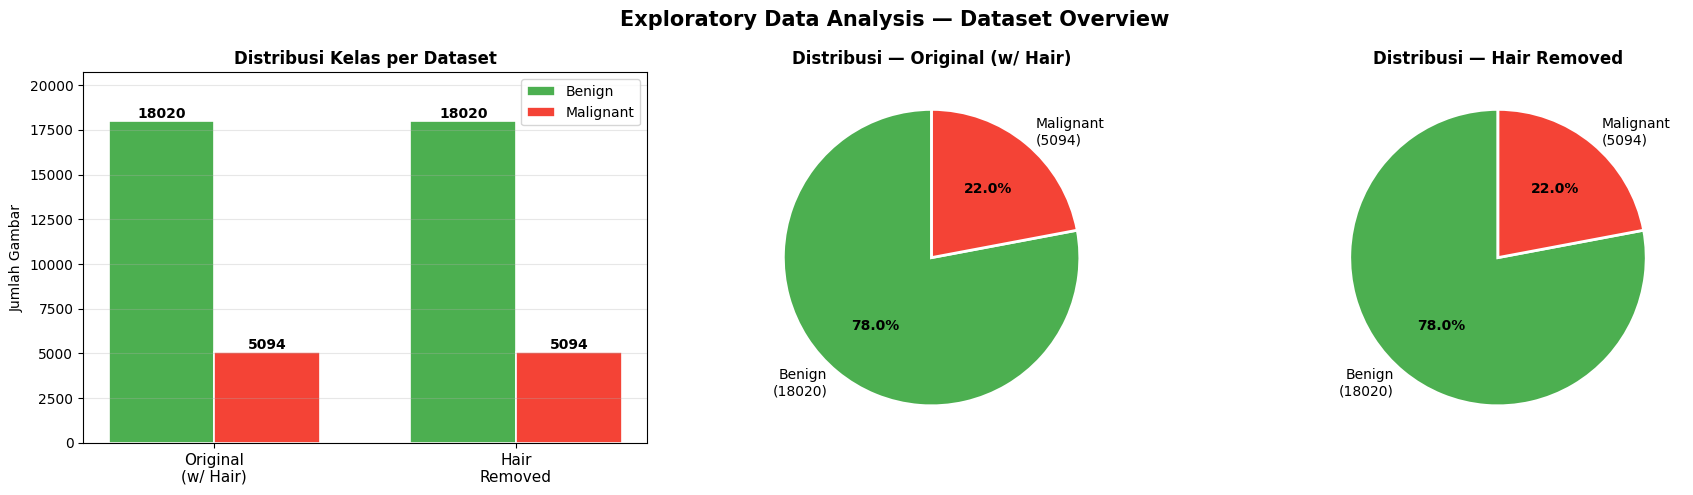


🔍 Menganalisis dimensi gambar (sampel 200 gambar)...


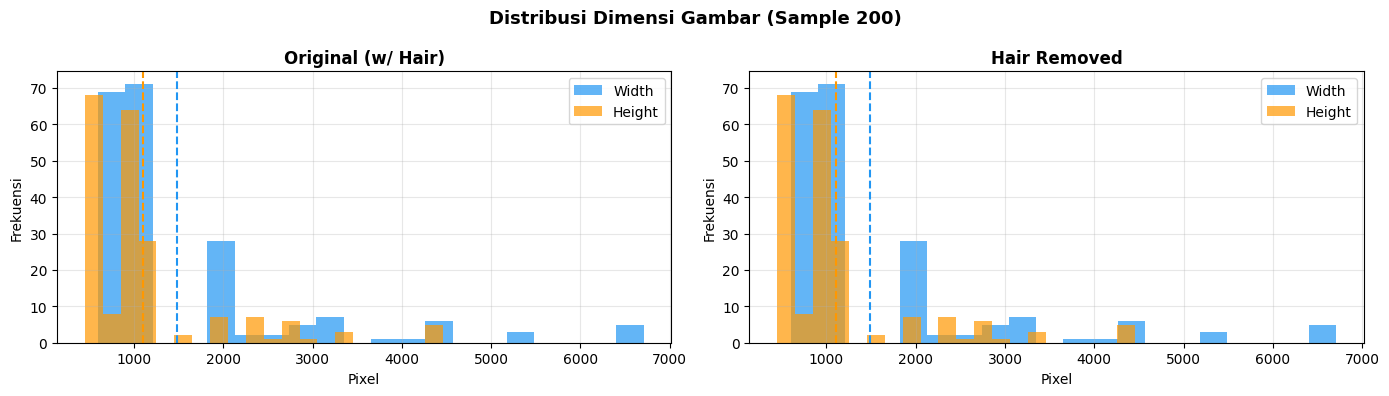


  Original  — Avg W: 1486px | Avg H: 1106px
  HairRemov — Avg W: 1486px | Avg H: 1106px


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Exploratory Data Analysis — Dataset Overview", fontsize=15, fontweight="bold")

ax = axes[0]
datasets   = ["Original\n(w/ Hair)", "Hair\nRemoved"]
benign_cnt = [
    len(df_original[df_original.label == "benign"]),
    len(df_hairrem [df_hairrem .label == "benign"]),
]
malign_cnt = [
    len(df_original[df_original.label == "malignant"]),
    len(df_hairrem [df_hairrem .label == "malignant"]),
]
x = np.arange(len(datasets))
w = 0.35
bars1 = ax.bar(x - w/2, benign_cnt,  w, label="Benign",    color="#4CAF50", edgecolor="white", linewidth=1.2)
bars2 = ax.bar(x + w/2, malign_cnt, w, label="Malignant", color="#F44336", edgecolor="white", linewidth=1.2)
for bar in bars1 + bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(int(bar.get_height())), ha="center", va="bottom", fontsize=10, fontweight="bold")
ax.set_title("Distribusi Kelas per Dataset", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(datasets, fontsize=11)
ax.set_ylabel("Jumlah Gambar"); ax.legend(); ax.set_ylim(0, max(benign_cnt + malign_cnt) * 1.15)
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
sizes  = [benign_cnt[0], malign_cnt[0]]
labels = [f"Benign\n({benign_cnt[0]})", f"Malignant\n({malign_cnt[0]})"]
colors = ["#4CAF50", "#F44336"]
wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, colors=colors, autopct="%1.1f%%",
    startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2)
)
for at in autotexts: at.set_fontweight("bold")
ax.set_title("Distribusi — Original (w/ Hair)", fontweight="bold")

ax = axes[2]
sizes  = [benign_cnt[1], malign_cnt[1]]
labels = [f"Benign\n({benign_cnt[1]})", f"Malignant\n({malign_cnt[1]})"]
wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, colors=colors, autopct="%1.1f%%",
    startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2)
)
for at in autotexts: at.set_fontweight("bold")
ax.set_title("Distribusi — Hair Removed", fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n🔍 Menganalisis dimensi gambar (sampel 200 gambar)...")

def sample_image_stats(df: pd.DataFrame, n: int = 200) -> dict:
    sample = df.sample(min(n, len(df)), random_state=SEED)
    widths, heights, channels = [], [], []
    for fp in sample["filepath"]:
        try:
            with Image.open(fp) as img:
                w, h = img.size
                ch = len(img.getbands())
                widths.append(w); heights.append(h); channels.append(ch)
        except Exception:
            pass
    return {"width": widths, "height": heights, "channel": channels}

stats_orig = sample_image_stats(df_original)
stats_hair = sample_image_stats(df_hairrem)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("Distribusi Dimensi Gambar (Sample 200)", fontsize=13, fontweight="bold")

for ax, stats, title in zip(axes, [stats_orig, stats_hair],
                             ["Original (w/ Hair)", "Hair Removed"]):
    ax.hist(stats["width"],  bins=20, alpha=0.7, label="Width",  color="#2196F3")
    ax.hist(stats["height"], bins=20, alpha=0.7, label="Height", color="#FF9800")
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("Pixel")
    ax.set_ylabel("Frekuensi"); ax.legend(); ax.grid(alpha=0.3)
    ax.axvline(np.mean(stats["width"]),  color="#2196F3", linestyle="--", linewidth=1.5)
    ax.axvline(np.mean(stats["height"]), color="#FF9800", linestyle="--", linewidth=1.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "eda_dimensions.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\n  Original  — Avg W: {np.mean(stats_orig['width']):.0f}px | Avg H: {np.mean(stats_orig['height']):.0f}px")
print(f"  HairRemov — Avg W: {np.mean(stats_hair['width']):.0f}px | Avg H: {np.mean(stats_hair['height']):.0f}px")

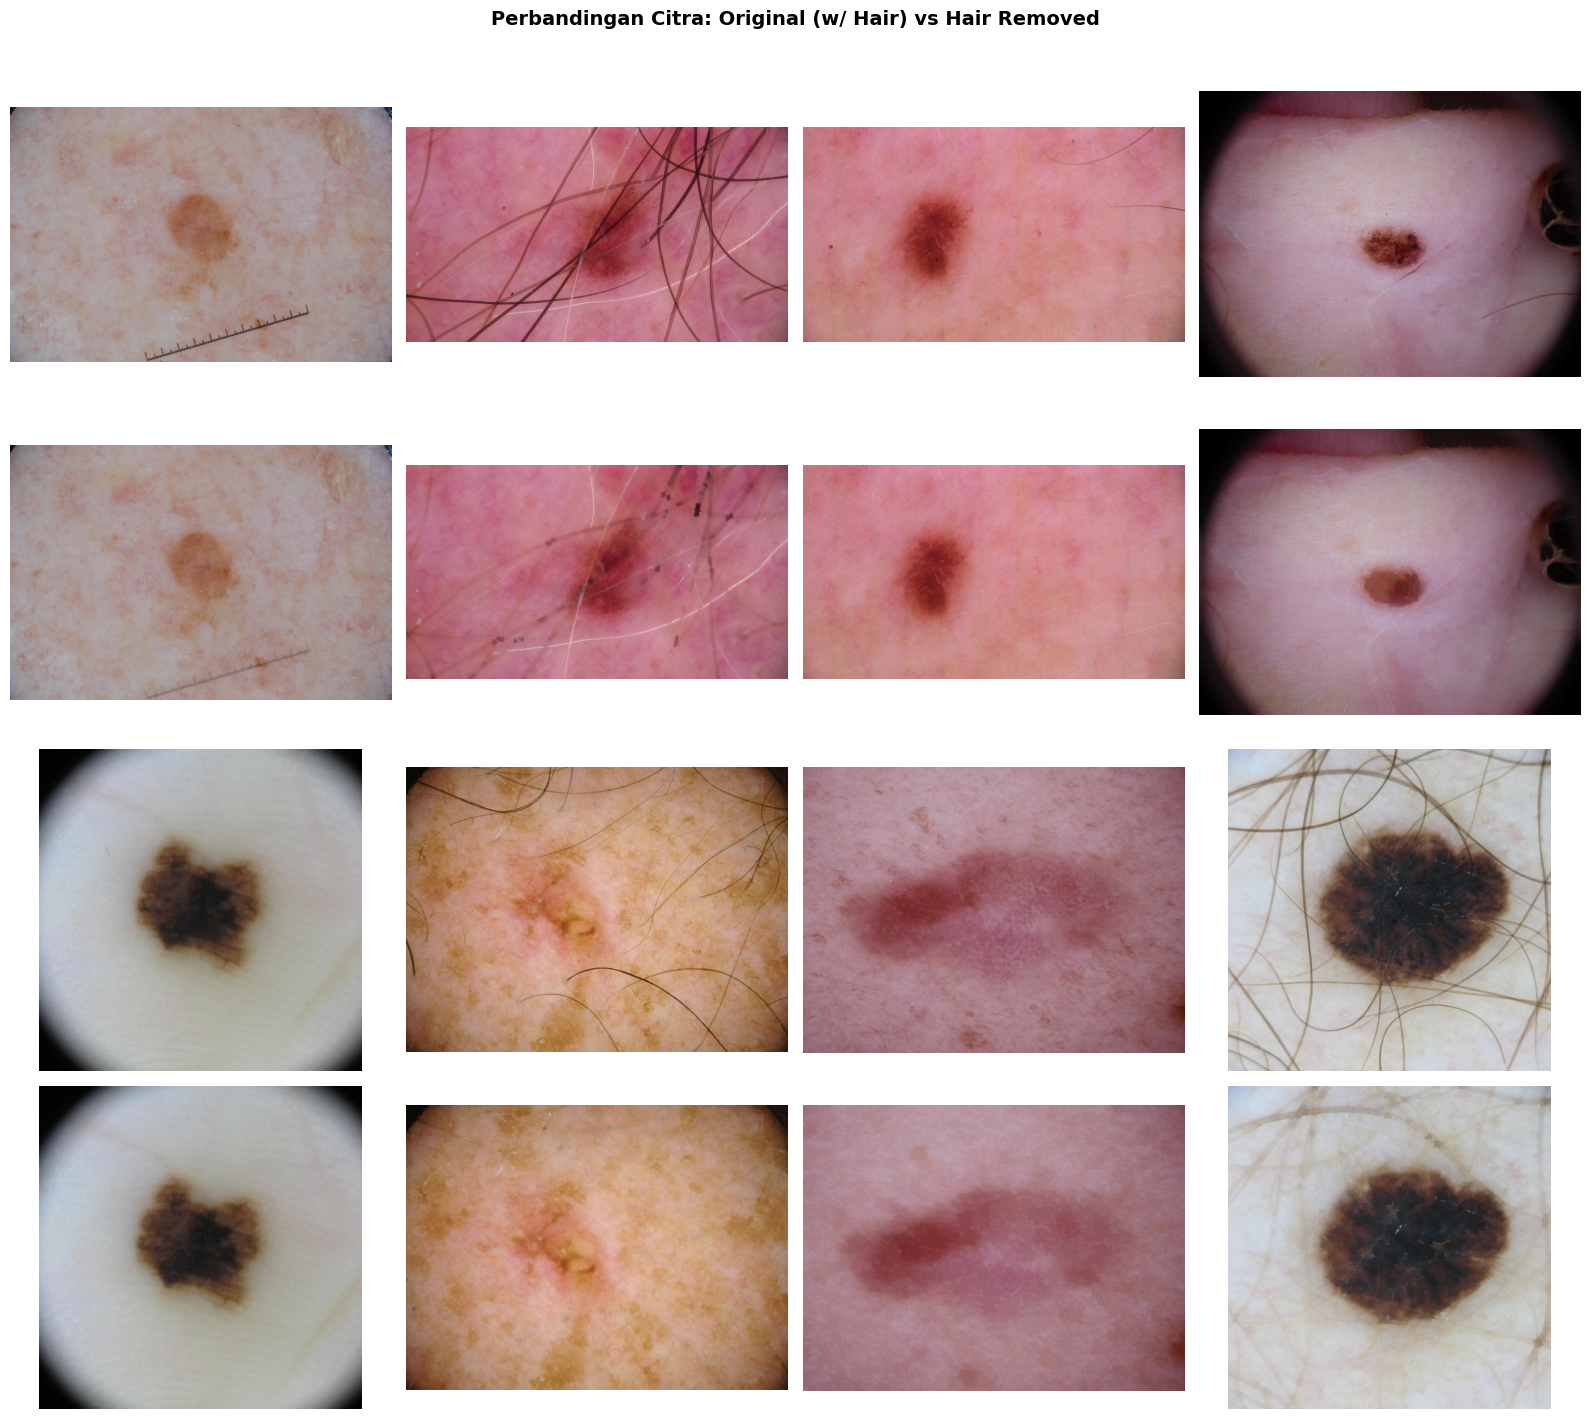


🎨 Menganalisis distribusi intensitas pixel...


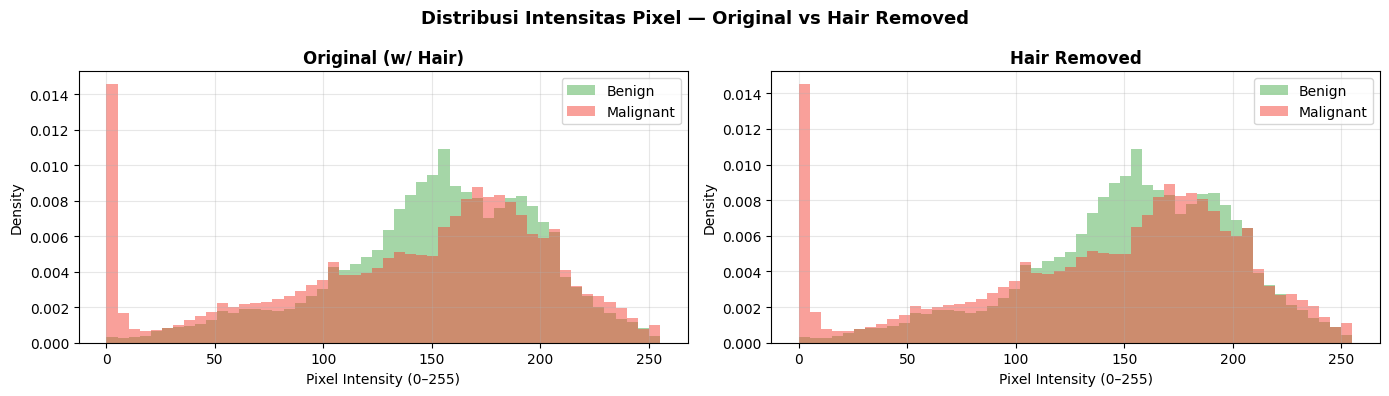

In [5]:
# VISUALISASI CONTOH GAMBAR

def show_sample_images(df_orig, df_hair, n_per_class=3):
    fig, axes = plt.subplots(
        nrows=4, ncols=n_per_class,
        figsize=(n_per_class * 4, 14)
    )
    fig.suptitle(
        "Perbandingan Citra: Original (w/ Hair) vs Hair Removed",
        fontsize=14, fontweight="bold", y=1.01
    )
    row_titles = [
        "Original — Benign",
        "Hair Removed — Benign",
        "Original — Malignant",
        "Hair Removed — Malignant",
    ]
    datasets_rows = [
        (df_orig, "benign"),
        (df_hair, "benign"),
        (df_orig, "malignant"),
        (df_hair, "malignant"),
    ]
    for row_idx, ((df, cls), row_title) in enumerate(zip(datasets_rows, row_titles)):
        subset = df[df.label == cls].sample(n_per_class, random_state=SEED).reset_index(drop=True)
        for col_idx in range(n_per_class):
            ax = axes[row_idx, col_idx]
            try:
                img = Image.open(subset.loc[col_idx, "filepath"]).convert("RGB")
                ax.imshow(img)
            except Exception as e:
                ax.text(0.5, 0.5, "Error", ha="center")
            ax.axis("off")
            if col_idx == 0:
                ax.set_ylabel(row_title, fontsize=11, fontweight="bold",
                              rotation=90, labelpad=10)
            color = "#4CAF50" if cls == "benign" else "#F44336"
            for spine in ax.spines.values():
                spine.set_edgecolor(color); spine.set_linewidth(3); spine.set_visible(True)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "sample_images_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()

show_sample_images(df_original, df_hairrem, n_per_class=4)

print("\n🎨 Menganalisis distribusi intensitas pixel...")

def get_pixel_intensity(df: pd.DataFrame, n: int = 100) -> list:
    all_pixels = []
    sample = df.sample(min(n, len(df)), random_state=SEED)
    for fp in sample["filepath"]:
        try:
            img = np.array(Image.open(fp).convert("RGB").resize((128, 128)))
            all_pixels.extend(img.flatten().tolist())
        except Exception:
            pass
    return all_pixels

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("Distribusi Intensitas Pixel — Original vs Hair Removed", fontsize=13, fontweight="bold")

for ax, df, title, color in zip(
    axes,
    [df_original, df_hairrem],
    ["Original (w/ Hair)", "Hair Removed"],
    ["#2196F3", "#FF5722"]
):
    for cls, c in [("benign", "#4CAF50"), ("malignant", "#F44336")]:
        pixels = get_pixel_intensity(df[df.label == cls], n=60)
        ax.hist(pixels, bins=50, alpha=0.5, label=cls.capitalize(), color=c, density=True)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Pixel Intensity (0–255)"); ax.set_ylabel("Density")
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pixel_intensity.png", dpi=150, bbox_inches="tight")
plt.show()

      DATA SPLIT (Stratified  —  70 / 15 / 15)

  [Original (w/ Hair)]  Total: 23114
    Train : 16179 (70.0%) | Benign: 12613, Malignant: 3566
    Val   :  3467 (15.0%) | Benign: 2703, Malignant: 764
    Test  :  3468 (15.0%) | Benign: 2704, Malignant: 764

  [Hair Removed]  Total: 23114
    Train : 16179 (70.0%) | Benign: 12613, Malignant: 3566
    Val   :  3467 (15.0%) | Benign: 2703, Malignant: 764
    Test  :  3468 (15.0%) | Benign: 2704, Malignant: 764


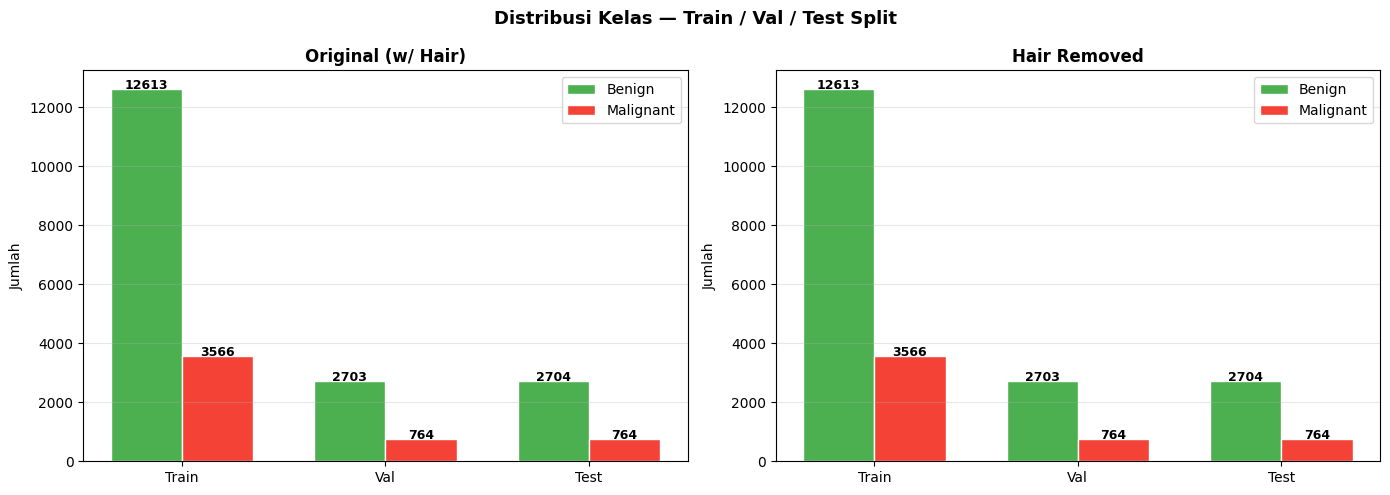

In [6]:
# DATA SPLITTING, SPLIT JADI Train, Val, Test (Stratified SUPAYA SEIMBANG)

def stratified_split(df: pd.DataFrame,
                     test_size: float = 0.15,
                     val_size: float  = 0.15,
                     seed: int = SEED):
    """Stratified split → train / val / test."""
    train_val, test = train_test_split(
        df, test_size=test_size, stratify=df["label_idx"], random_state=seed
    )
    val_ratio = val_size / (1 - test_size)
    train, val = train_test_split(
        train_val, test_size=val_ratio, stratify=train_val["label_idx"], random_state=seed
    )
    train = train.reset_index(drop=True)
    val   = val  .reset_index(drop=True)
    test  = test .reset_index(drop=True)
    return train, val, test

train_orig, val_orig, test_orig = stratified_split(df_original)
train_hair, val_hair, test_hair = stratified_split(df_hairrem)

def print_split_info(train, val, test, name):
    total = len(train) + len(val) + len(test)
    print(f"\n  [{name}]  Total: {total}")
    print(f"    Train : {len(train):>5} ({len(train)/total*100:.1f}%) "
          f"| Benign: {sum(train.label=='benign')}, Malignant: {sum(train.label=='malignant')}")
    print(f"    Val   : {len(val):>5} ({len(val)/total*100:.1f}%) "
          f"| Benign: {sum(val.label=='benign')}, Malignant: {sum(val.label=='malignant')}")
    print(f"    Test  : {len(test):>5} ({len(test)/total*100:.1f}%) "
          f"| Benign: {sum(test.label=='benign')}, Malignant: {sum(test.label=='malignant')}")

print("=" * 60)
print("      DATA SPLIT (Stratified  —  70 / 15 / 15)")
print("=" * 60)
print_split_info(train_orig, val_orig, test_orig, "Original (w/ Hair)")
print_split_info(train_hair, val_hair, test_hair, "Hair Removed")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Distribusi Kelas — Train / Val / Test Split", fontsize=13, fontweight="bold")

splits_label = ["Train", "Val", "Test"]
palette      = {"benign": "#4CAF50", "malignant": "#F44336"}

for ax, (train, val, test), title in zip(
    axes,
    [(train_orig, val_orig, test_orig), (train_hair, val_hair, test_hair)],
    ["Original (w/ Hair)", "Hair Removed"]
):
    x = np.arange(3)
    w = 0.35
    counts_b = [sum(s.label=="benign")    for s in [train, val, test]]
    counts_m = [sum(s.label=="malignant") for s in [train, val, test]]
    b1 = ax.bar(x - w/2, counts_b, w, label="Benign",    color="#4CAF50", edgecolor="white")
    b2 = ax.bar(x + w/2, counts_m, w, label="Malignant", color="#F44336", edgecolor="white")
    for bar in list(b1) + list(b2):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(int(bar.get_height())), ha="center", fontsize=9, fontweight="bold")
    ax.set_title(title, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(splits_label)
    ax.set_ylabel("Jumlah"); ax.legend(); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "split_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

✅ DataLoader berhasil dibuat!
   Original  — Train: 16179, Val: 3467, Test: 3468
   HairRemov — Train: 16179, Val: 3467, Test: 3468


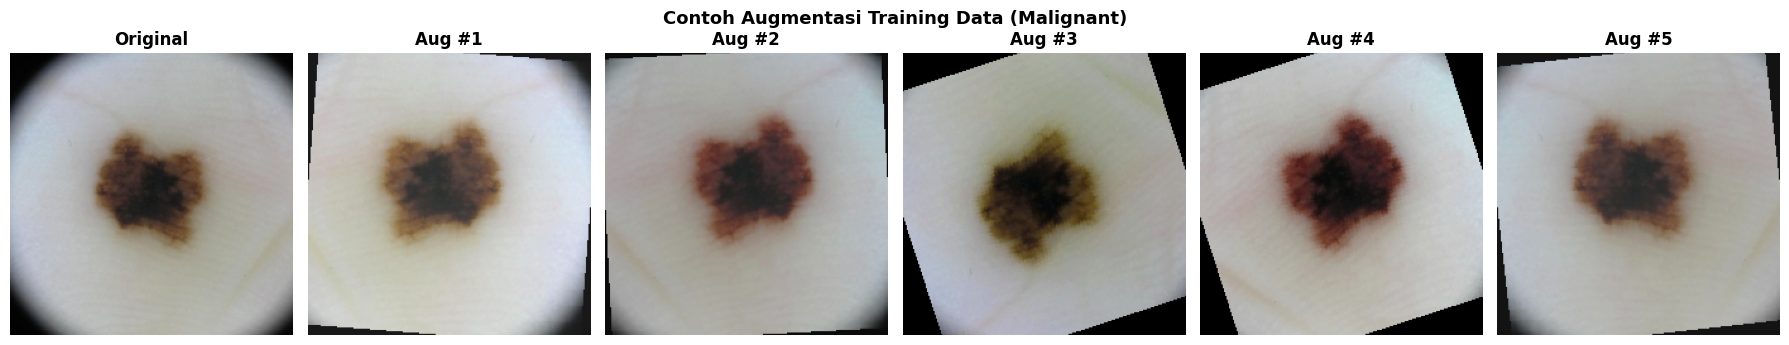

In [7]:
# Preprocessing Pipeline & Augmentasi

IMG_SIZE   = 224
BATCH_SIZE = 32
NUM_EPOCHS = 30
LR_INIT    = 1e-3
LR_FINETUNE = 1e-4
PATIENCE   = 7

MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 20, IMG_SIZE + 20)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.3),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.05),
    transforms.RandomGrayscale(p=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class MelanomaDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["filepath"]).convert("RGB")
        label = int(row["label_idx"])
        if self.transform:
            image = self.transform(image)
        return image, label

def make_weighted_sampler(df: pd.DataFrame) -> WeightedRandomSampler:
    class_counts  = df["label_idx"].value_counts().sort_index().values
    class_weights = 1.0 / class_counts
    sample_weights = [class_weights[idx] for idx in df["label_idx"]]
    return WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True
    )

def build_loaders(train_df, val_df, test_df, batch_size=BATCH_SIZE):
    sampler = make_weighted_sampler(train_df)

    train_ds = MelanomaDataset(train_df, train_transforms)
    val_ds   = MelanomaDataset(val_df,   val_test_transforms)
    test_ds  = MelanomaDataset(test_df,  val_test_transforms)

    train_loader = DataLoader(train_ds, batch_size=batch_size,
                              sampler=sampler, num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size,
                              shuffle=False, num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size,
                              shuffle=False, num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader

loaders_orig = build_loaders(train_orig, val_orig, test_orig)
loaders_hair = build_loaders(train_hair, val_hair, test_hair)

print("✅ DataLoader berhasil dibuat!")
print(f"   Original  — Train: {len(loaders_orig[0].dataset)}, Val: {len(loaders_orig[1].dataset)}, Test: {len(loaders_orig[2].dataset)}")
print(f"   HairRemov — Train: {len(loaders_hair[0].dataset)}, Val: {len(loaders_hair[1].dataset)}, Test: {len(loaders_hair[2].dataset)}")

def visualize_augmentation(df: pd.DataFrame, n_aug: int = 5):
    """Tampilkan satu gambar + versi augmented-nya."""
    sample_fp = df[df.label == "malignant"].sample(1, random_state=SEED).iloc[0]["filepath"]
    orig_img  = Image.open(sample_fp).convert("RGB")

    fig, axes = plt.subplots(1, n_aug + 1, figsize=(18, 3.5))
    fig.suptitle("Contoh Augmentasi Training Data (Malignant)", fontsize=13, fontweight="bold")

    axes[0].imshow(orig_img.resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title("Original", fontweight="bold"); axes[0].axis("off")
    for i in range(1, n_aug + 1):
        aug = train_transforms(orig_img)
        aug = aug * torch.tensor(STD).view(3,1,1) + torch.tensor(MEAN).view(3,1,1)
        aug = aug.permute(1,2,0).numpy().clip(0,1)
        axes[i].imshow(aug)
        axes[i].set_title(f"Aug #{i}", fontweight="bold"); axes[i].axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "augmentation_sample.png", dpi=150, bbox_inches="tight")
    plt.show()

visualize_augmentation(df_original)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 98.6MB/s]


           MODEL ARCHITECTURE SUMMARY

  📌 EfficientNet-B0
     Total params    :    4,336,510
     Trainable params :      328,962
     Frozen params   :    4,007,548

  📌 MobileNetV2
     Total params    :    2,552,834
     Trainable params :      328,962
     Frozen params   :    2,223,872


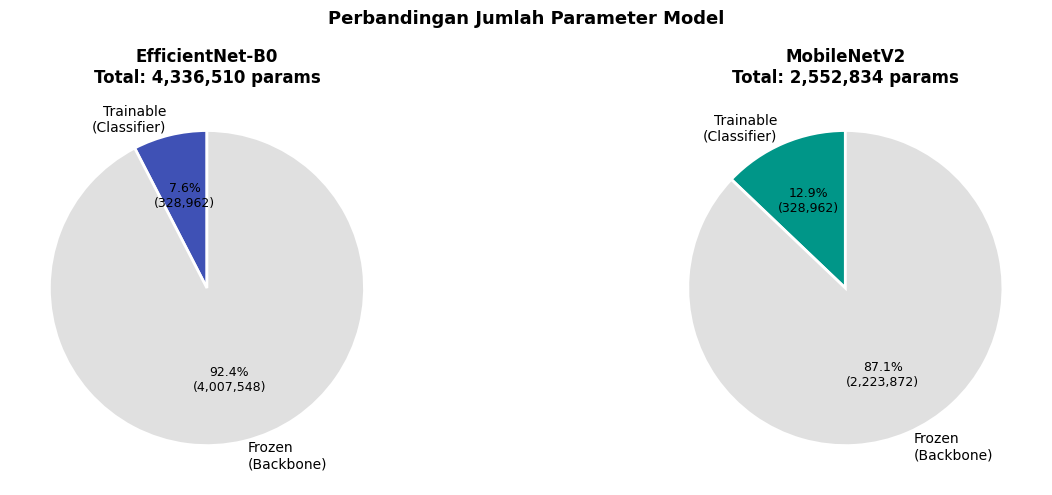


✅ Forward pass OK — EfficientNet output: torch.Size([2, 2])
✅ Forward pass OK — MobileNetV2  output: torch.Size([2, 2])


In [8]:
# MODEL ARSITEKTUR

def build_efficientnet_b0(num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    """
    EfficientNet-B0 dengan custom classifier head.
    Compound scaling: depth α=1.2, width β=1.1, resolution γ=1.15
    """
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    )
    
    for param in model.parameters():
        param.requires_grad = False

    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.4, inplace=True),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.BatchNorm1d(256),
        nn.Dropout(p=0.3),
        nn.Linear(256, num_classes)
    )
    return model

def build_mobilenetv2(num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    """
    MobileNetV2 dengan custom classifier head.
    Menggunakan depthwise separable convolution.
    """
    model = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None
    )
    for param in model.parameters():
        param.requires_grad = False

    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.BatchNorm1d(256),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )
    return model

def count_parameters(model: nn.Module) -> dict:
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": trainable, "frozen": total - trainable}

effnet  = build_efficientnet_b0()
mobilev2 = build_mobilenetv2()

eff_params  = count_parameters(effnet)
mob_params  = count_parameters(mobilev2)

print("=" * 60)
print("           MODEL ARCHITECTURE SUMMARY")
print("=" * 60)
print(f"\n  📌 EfficientNet-B0")
print(f"     Total params    : {eff_params['total']:>12,}")
print(f"     Trainable params : {eff_params['trainable']:>12,}")
print(f"     Frozen params   : {eff_params['frozen']:>12,}")

print(f"\n  📌 MobileNetV2")
print(f"     Total params    : {mob_params['total']:>12,}")
print(f"     Trainable params : {mob_params['trainable']:>12,}")
print(f"     Frozen params   : {mob_params['frozen']:>12,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Perbandingan Jumlah Parameter Model", fontsize=13, fontweight="bold")

for ax, params, name, color in zip(
    axes,
    [eff_params, mob_params],
    ["EfficientNet-B0", "MobileNetV2"],
    ["#3F51B5", "#009688"]
):
    labels = ["Trainable\n(Classifier)", "Frozen\n(Backbone)"]
    values = [params["trainable"], params["frozen"]]
    colors_pie = [color, "#E0E0E0"]
    wedges, texts, autotexts = ax.pie(
        values, labels=labels, colors=colors_pie,
        autopct=lambda p: f"{p:.1f}%\n({int(p/100*params['total']):,})",
        startangle=90, wedgeprops=dict(edgecolor="white", linewidth=2)
    )
    for at in autotexts: at.set_fontsize(9)
    ax.set_title(f"{name}\nTotal: {params['total']:,} params", fontweight="bold")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_parameters.png", dpi=150, bbox_inches="tight")
plt.show()

dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE)
with torch.no_grad():
    out_eff  = effnet(dummy)
    out_mob  = mobilev2(dummy)
print(f"\n✅ Forward pass OK — EfficientNet output: {out_eff.shape}")
print(f"✅ Forward pass OK — MobileNetV2  output: {out_mob.shape}")

del effnet, mobilev2

In [9]:
# INI CUMA UNTUK AWK CARI TAU KENAPA GPU AWK GA KEPAKE

import torch
import subprocess

print("=" * 55)
print("           GPU DIAGNOSIS")
print("=" * 55)

print(f"\n[1] CUDA available     : {torch.cuda.is_available()}")
print(f"    CUDA device count  : {torch.cuda.device_count()}")
print(f"    Current device     : {torch.cuda.current_device()}")
print(f"    Device name        : {torch.cuda.get_device_name(0)}")

print(f"\n[2] DEVICE variable    : {DEVICE}")
print(f"    DEVICE type        : {DEVICE.type}")

dummy_model = build_efficientnet_b0().to(DEVICE)
first_param = next(dummy_model.parameters())
print(f"\n[3] Model parameter device : {first_param.device}")
print(f"    Model benar di GPU     : {first_param.is_cuda}")
del dummy_model

dummy_tensor = torch.randn(2, 3, 224, 224).to(DEVICE)
print(f"\n[4] Tensor device      : {dummy_tensor.device}")
print(f"    Tensor di GPU      : {dummy_tensor.is_cuda}")
del dummy_tensor

print(f"\n[5] GPU Memory:")
print(f"    Allocated : {torch.cuda.memory_allocated(0) / 1e9:.3f} GB")
print(f"    Reserved  : {torch.cuda.memory_reserved(0) / 1e9:.3f} GB")
print(f"    Total     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

print(f"\n[6] nvidia-smi output:")
result = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used,memory.total",
     "--format=csv,noheader"],
    capture_output=True, text=True
)
print(f"    {result.stdout.strip()}")

print(f"\n[7] Speed Test — GPU vs CPU forward pass:")
model_test = build_efficientnet_b0().eval()
dummy_in   = torch.randn(16, 3, 224, 224)

model_test_cpu = model_test.cpu()
t0 = time.time()
with torch.no_grad():
    _ = model_test_cpu(dummy_in.cpu())
print(f"    CPU forward (batch=16): {(time.time()-t0)*1000:.1f} ms")

model_test_gpu = model_test.to(DEVICE)
dummy_in_gpu   = dummy_in.to(DEVICE)
torch.cuda.synchronize()
t0 = time.time()
with torch.no_grad():
    _ = model_test_gpu(dummy_in_gpu)
torch.cuda.synchronize()
print(f"    GPU forward (batch=16): {(time.time()-t0)*1000:.1f} ms")

del model_test, model_test_cpu, model_test_gpu
torch.cuda.empty_cache()
print("\n✅ Diagnosis selesai!")

           GPU DIAGNOSIS

[1] CUDA available     : True
    CUDA device count  : 2
    Current device     : 0
    Device name        : Tesla T4

[2] DEVICE variable    : cuda
    DEVICE type        : cuda

[3] Model parameter device : cuda:0
    Model benar di GPU     : True

[4] Tensor device      : cuda:0
    Tensor di GPU      : True

[5] GPU Memory:
    Allocated : 0.000 GB
    Reserved  : 0.036 GB
    Total     : 15.6 GB

[6] nvidia-smi output:
    Tesla T4, 5 %, 139 MiB, 15360 MiB
Tesla T4, 0 %, 3 MiB, 15360 MiB

[7] Speed Test — GPU vs CPU forward pass:
    CPU forward (batch=16): 527.0 ms
    GPU forward (batch=16): 806.0 ms

✅ Diagnosis selesai!


In [18]:
# Training Engine

class EarlyStopping:
    """Stop training jika val_loss tidak membaik selama 'patience' epoch."""
    def __init__(self, patience: int = PATIENCE, delta: float = 1e-4, verbose: bool = True):
        self.patience = patience
        self.delta    = delta
        self.verbose  = verbose
        self.counter  = 0
        self.best_score = None
        self.early_stop = False
        self.best_val_loss = np.inf

    def __call__(self, val_loss, model, path):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model, path)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f"     ⏳ EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(val_loss, model, path)
            self.counter = 0

    def save_checkpoint(self, val_loss, model, path):
        torch.save(model.state_dict(), path)
        if self.verbose:
            print(f"     💾 Model tersimpan (val_loss: {val_loss:.4f})")
        self.best_val_loss = val_loss

@torch.no_grad()
def evaluate_test(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss    = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        probs = F.softmax(outputs.float(), dim=1)[:, 1]
        preds = outputs.float().argmax(dim=1)

        all_probs .extend(probs .cpu().numpy())
        all_preds .extend(preds .cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc      = accuracy_score(all_labels, all_preds)
    return avg_loss, acc, all_labels, all_preds, all_probs

DEVICE = torch.device("cuda:0")
torch.cuda.set_device(0)
torch.cuda.empty_cache()

print("=" * 55)
print("  KONFIGURASI SINGLE GPU (No DataParallel)")
print("=" * 55)
print(f"  Device  : {torch.cuda.get_device_name(0)}")
print(f"  VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

BATCH_SIZE_TRAIN = 128
BATCH_SIZE_EVAL  = 256

print(f"  Batch (train) : {BATCH_SIZE_TRAIN}")
print(f"  Batch (eval)  : {BATCH_SIZE_EVAL}")

print("\n🔥 Benchmark Single GPU (no DataParallel)...")
_m = build_efficientnet_b0().to(DEVICE).eval()
_x = torch.randn(BATCH_SIZE_TRAIN, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

with torch.no_grad():
    with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
        for _ in range(5): _m(_x)
torch.cuda.synchronize()

_times = []
with torch.no_grad():
    with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
        for _ in range(20):
            torch.cuda.synchronize()
            t0 = time.time()
            _m(_x)
            torch.cuda.synchronize()
            _times.append(time.time() - t0)

_avg = np.mean(_times) * 1000
print(f"  EfficientNet-B0 forward (batch={BATCH_SIZE_TRAIN}): {_avg:.1f} ms")
print(f"  Throughput : {BATCH_SIZE_TRAIN/(_avg/1000):.0f} images/sec")
print(f"  Per image  : {_avg/BATCH_SIZE_TRAIN:.2f} ms")

del _m, _x, _times
torch.cuda.empty_cache()

N_WORKERS = min(4, os.cpu_count() or 2)

def build_loaders_final(train_df, val_df, test_df):
    sampler  = make_weighted_sampler(train_df)
    train_ds = MelanomaDataset(train_df, train_transforms)
    val_ds   = MelanomaDataset(val_df,   val_test_transforms)
    test_ds  = MelanomaDataset(test_df,  val_test_transforms)

    kw = dict(
        num_workers        = N_WORKERS,
        pin_memory         = True,
        persistent_workers = True,
        prefetch_factor    = 4,
    )
    return (
        DataLoader(train_ds, batch_size=BATCH_SIZE_TRAIN,
                   sampler=sampler, drop_last=True, **kw),
        DataLoader(val_ds,   batch_size=BATCH_SIZE_EVAL,
                   shuffle=False, **kw),
        DataLoader(test_ds,  batch_size=BATCH_SIZE_EVAL,
                   shuffle=False, **kw),
    )

loaders_orig = build_loaders_final(train_orig, val_orig, test_orig)
loaders_hair = build_loaders_final(train_hair, val_hair, test_hair)
print("\n✅ DataLoaders rebuilt (single GPU config)")

def train_one_epoch_final(model, loader, criterion, optimizer, scaler):
    model.train()
    total_loss = 0.0
    all_preds, all_labels = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        all_preds .extend(outputs.detach().argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return total_loss / len(loader.dataset), accuracy_score(all_labels, all_preds)

@torch.no_grad()
def evaluate_final(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds, all_labels, all_probs = [], [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(device_type="cuda", dtype=torch.float16):
            outputs = model(images)
            loss    = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)
        all_probs .extend(F.softmax(outputs.float(), dim=1)[:, 1].cpu().numpy())
        all_preds .extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return (total_loss / len(loader.dataset),
            accuracy_score(all_labels, all_preds),
            all_labels, all_preds, all_probs)


def train_model_final(model, model_name, train_loader, val_loader,
                      save_path, num_epochs=NUM_EPOCHS,
                      lr_phase1=LR_INIT, lr_phase2=LR_FINETUNE,
                      patience=PATIENCE):

    model = model.to(DEVICE)
    assert next(model.parameters()).is_cuda

    y_train  = train_loader.dataset.df["label_idx"].values
    counts   = np.bincount(y_train)
    w        = torch.tensor(len(y_train) / (len(counts) * counts),
                            dtype=torch.float32).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=w)
    scaler    = torch.amp.GradScaler(device="cuda")

    PHASE_SWITCH = 10

    for p in model.parameters(): p.requires_grad = False
    for p in model.classifier.parameters(): p.requires_grad = True

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr_phase1, weight_decay=1e-4
    )
    scheduler  = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=PHASE_SWITCH, eta_min=1e-5
    )
    early_stop = EarlyStopping(patience=patience, verbose=True)
    history    = {k: [] for k in
                  ["train_loss","val_loss","train_acc","val_acc","lr","phase"]}

    print(f"\n{'='*62}")
    print(f"  🚀 {model_name}")
    print(f"  GPU : {torch.cuda.get_device_name(0)} | "
          f"Batch: {train_loader.batch_size} | "
          f"AMP : ✅ | DataParallel: ❌")
    print(f"{'='*62}")
    print(f"  [Phase 1] Epoch 1–{PHASE_SWITCH}: Classifier only (backbone frozen)")

    t_total = time.time()

    for epoch in range(1, num_epochs + 1):

        if epoch == PHASE_SWITCH + 1:
            print(f"\n  {'─'*55}")
            print(f"  [Phase 2] Epoch {epoch}–{num_epochs}: Full fine-tune (LR={lr_phase2})")
            for p in model.parameters(): p.requires_grad = True
            optimizer = optim.AdamW(
                model.parameters(), lr=lr_phase2, weight_decay=1e-4
            )
            scheduler  = optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=num_epochs - PHASE_SWITCH, eta_min=1e-6
            )
            early_stop = EarlyStopping(patience=patience, verbose=True)
            print(f"  {'─'*55}\n")

        phase = 1 if epoch <= PHASE_SWITCH else 2
        t0    = time.time()

        tr_loss, tr_acc = train_one_epoch_final(
            model, train_loader, criterion, optimizer, scaler
        )
        vl_loss, vl_acc, *_ = evaluate_final(
            model, val_loader, criterion
        )
        scheduler.step()

        elapsed    = time.time() - t0
        current_lr = optimizer.param_groups[0]["lr"]
        gpu_util   = torch.cuda.utilization(0)
        vram_gb    = torch.cuda.memory_allocated(0) / 1e9

        history["train_loss"].append(tr_loss)
        history["val_loss"]  .append(vl_loss)
        history["train_acc"] .append(tr_acc)
        history["val_acc"]   .append(vl_acc)
        history["lr"]        .append(current_lr)
        history["phase"]     .append(phase)

        print(f"  [P{phase}] Ep {epoch:>3}/{num_epochs} | "
              f"Loss T:{tr_loss:.4f} V:{vl_loss:.4f} | "
              f"Acc T:{tr_acc:.4f} V:{vl_acc:.4f} | "
              f"GPU:{gpu_util:>2}% {vram_gb:.1f}GB | "
              f"⏱ {elapsed:.1f}s")

        early_stop(vl_loss, model, save_path)
        if early_stop.early_stop:
            print(f"\n  ⛔ Early stopping epoch {epoch}")
            break

    t_total = time.time() - t_total
    model.load_state_dict(torch.load(save_path, map_location=DEVICE))
    torch.cuda.empty_cache()
    print(f"\n  ✅ Selesai: {t_total/60:.1f} menit | "
          f"Best val_loss: {early_stop.best_val_loss:.4f}")
    return model, history, t_total

  KONFIGURASI SINGLE GPU (No DataParallel)
  Device  : Tesla T4
  VRAM    : 15.6 GB
  Batch (train) : 128
  Batch (eval)  : 256

🔥 Benchmark Single GPU (no DataParallel)...
  EfficientNet-B0 forward (batch=128): 82.6 ms
  Throughput : 1549 images/sec
  Per image  : 0.65 ms

✅ DataLoaders rebuilt (single GPU config)


In [13]:
trained_models = {}
all_histories  = {}
training_times = {}

print("READY TO TRAIN . . .")

In [23]:

# Latih EfficientNet-B0
#   1. EfficientNet-B0 Original
#   2. EfficientNet-B0 Hair Removed

CONFIGS_EFFNET = [
    {
        "name"     : "EfficientNet-B0_Original",
        "builder"  : build_efficientnet_b0,
        "loaders"  : loaders_orig,
        "save_path": str(OUTPUT_DIR / "effnet_original.pth"),
    },
    {
        "name"     : "EfficientNet-B0_HairRemoved",
        "builder"  : build_efficientnet_b0,
        "loaders"  : loaders_hair,
        "save_path": str(OUTPUT_DIR / "effnet_hairrem.pth"),
    },
]

for cfg in CONFIGS_EFFNET:
    set_seed()
    torch.cuda.empty_cache()

    model = cfg["builder"]().to(DEVICE)
    train_loader, val_loader, _ = cfg["loaders"]

    model, history, t = train_model_final(
        model        = model,
        model_name   = cfg["name"],
        train_loader = train_loader,
        val_loader   = val_loader,
        save_path    = cfg["save_path"],
        num_epochs   = NUM_EPOCHS,
    )

    trained_models[cfg["name"]] = model
    all_histories [cfg["name"]] = history
    training_times[cfg["name"]] = t

print("\n" + "="*55)
print("✅ EfficientNet-B0 selesai dilatih!")
print("="*55)
for name, t in training_times.items():
    print(f"  {name:<40}: {t/60:.1f} menit")


  🚀 EfficientNet-B0_Original
  GPU : Tesla T4 | Batch: 128 | AMP : ✅ | DataParallel: ❌
  [Phase 1] Epoch 1–10: Classifier only (backbone frozen)
  [P1] Ep   1/30 | Loss T:0.4142 V:0.5449 | Acc T:0.7217 V:0.5800 | GPU:80% 0.1GB | ⏱ 227.3s
     💾 Model tersimpan (val_loss: 0.5449)
  [P1] Ep   2/30 | Loss T:0.3618 V:0.5088 | Acc T:0.7194 V:0.5985 | GPU:69% 0.1GB | ⏱ 225.4s
     💾 Model tersimpan (val_loss: 0.5088)
  [P1] Ep   3/30 | Loss T:0.3527 V:0.5267 | Acc T:0.7191 V:0.5760 | GPU:91% 0.1GB | ⏱ 229.1s
     ⏳ EarlyStopping counter: 1/7
  [P1] Ep   4/30 | Loss T:0.3426 V:0.5396 | Acc T:0.7258 V:0.5763 | GPU:100% 0.1GB | ⏱ 228.0s
     ⏳ EarlyStopping counter: 2/7
  [P1] Ep   5/30 | Loss T:0.3316 V:0.5075 | Acc T:0.7330 V:0.6077 | GPU:66% 0.1GB | ⏱ 227.6s
     💾 Model tersimpan (val_loss: 0.5075)
  [P1] Ep   6/30 | Loss T:0.3354 V:0.5187 | Acc T:0.7287 V:0.5904 | GPU:67% 0.1GB | ⏱ 224.4s
     ⏳ EarlyStopping counter: 1/7
  [P1] Ep   7/30 | Loss T:0.3352 V:0.5065 | Acc T:0.7298 V:0.6069 |

In [14]:
# Latih MobileNetV2
#   3. MobileNetV2 — Original
#   4. MobileNetV2 — Hair Removed

CONFIGS_MOBILENET = [
    {
        "name"     : "MobileNetV2_Original",
        "builder"  : build_mobilenetv2,
        "loaders"  : loaders_orig,
        "save_path": str(OUTPUT_DIR / "mobilev2_original.pth"),
    },
    {
        "name"     : "MobileNetV2_HairRemoved",
        "builder"  : build_mobilenetv2,
        "loaders"  : loaders_hair,
        "save_path": str(OUTPUT_DIR / "mobilev2_hairrem.pth"),
    },
]

for cfg in CONFIGS_MOBILENET:
    set_seed()
    torch.cuda.empty_cache()

    model = cfg["builder"]().to(DEVICE)
    train_loader, val_loader, _ = cfg["loaders"]

    model, history, t = train_model_final(
        model        = model,
        model_name   = cfg["name"],
        train_loader = train_loader,
        val_loader   = val_loader,
        save_path    = cfg["save_path"],
        num_epochs   = NUM_EPOCHS,
    )

    trained_models[cfg["name"]] = model
    all_histories [cfg["name"]] = history
    training_times[cfg["name"]] = t

print("\n" + "="*55)
print("✅ MobileNetV2 selesai dilatih!")
print("="*55)
for name, t in training_times.items():
    print(f"  {name:<40}: {t/60:.1f} menit")

print(f"\n📦 Total model tersimpan : {len(trained_models)}")
for name in trained_models:
    print(f"   ✅ {name}")


  🚀 MobileNetV2_Original
  GPU : Tesla T4 | Batch: 128 | AMP : ✅ | DataParallel: ❌
  [Phase 1] Epoch 1–10: Classifier only (backbone frozen)
  [P1] Ep   1/30 | Loss T:0.3945 V:0.7062 | Acc T:0.7220 V:0.5114 | GPU:75% 0.0GB | ⏱ 301.5s
     💾 Model tersimpan (val_loss: 0.7062)
  [P1] Ep   2/30 | Loss T:0.3505 V:0.5825 | Acc T:0.7210 V:0.5567 | GPU:86% 0.0GB | ⏱ 293.9s
     💾 Model tersimpan (val_loss: 0.5825)
  [P1] Ep   3/30 | Loss T:0.3412 V:0.5633 | Acc T:0.7269 V:0.5803 | GPU:97% 0.0GB | ⏱ 306.1s
     💾 Model tersimpan (val_loss: 0.5633)
  [P1] Ep   4/30 | Loss T:0.3357 V:0.5964 | Acc T:0.7272 V:0.5451 | GPU:100% 0.0GB | ⏱ 297.3s
     ⏳ EarlyStopping counter: 1/7
  [P1] Ep   5/30 | Loss T:0.3355 V:0.5834 | Acc T:0.7287 V:0.5645 | GPU:86% 0.0GB | ⏱ 307.7s
     ⏳ EarlyStopping counter: 2/7
  [P1] Ep   6/30 | Loss T:0.3274 V:0.5644 | Acc T:0.7382 V:0.5607 | GPU:100% 0.0GB | ⏱ 303.8s
     ⏳ EarlyStopping counter: 3/7
  [P1] Ep   7/30 | Loss T:0.3298 V:0.5805 | Acc T:0.7309 V:0.5333 | GP

In [21]:
# EVAL DI TEST SET

criterion_eval = nn.CrossEntropyLoss()

def build_test_loader(test_df, batch_size=BATCH_SIZE_EVAL):
    test_ds = MelanomaDataset(test_df, val_test_transforms)
    return DataLoader(
        test_ds,
        batch_size  = batch_size,
        shuffle     = False,
        num_workers = 2,           
        pin_memory  = True,
        persistent_workers = False,
    )

test_loader_orig = build_test_loader(test_orig)
test_loader_hair = build_test_loader(test_hair)

test_loaders_map = {
    "EfficientNet-B0_Original"   : test_loader_orig,
    "EfficientNet-B0_HairRemoved": test_loader_hair,
    "MobileNetV2_Original"       : test_loader_orig,
    "MobileNetV2_HairRemoved"    : test_loader_hair,
}

print("✅ Test loaders baru berhasil dibuat (persistent_workers=False)")

results = {}

print("\n" + "=" * 62)
print("   EVALUASI KOMPREHENSIF — TEST SET")
print("=" * 62)
print(f"   Device : {torch.cuda.get_device_name(0)}")
print(f"   AMP    : ✅  |  non_blocking : ✅")
print("=" * 62)

for name, model in trained_models.items():
    print(f"\n  ▶ {name}")

    model = model.to(DEVICE)
    model.eval()
    test_loader = test_loaders_map[name]

    torch.cuda.synchronize()
    t_start = time.time()

    _, _, y_true, y_pred, y_prob = evaluate_test(
        model, test_loader, criterion_eval, DEVICE
    )

    torch.cuda.synchronize()
    inference_time = time.time() - t_start
    n_samples      = len(y_true)

    acc       = accuracy_score (y_true, y_pred)
    prec      = precision_score(y_true, y_pred, average="binary", zero_division=0)
    rec       = recall_score   (y_true, y_pred, average="binary", zero_division=0)
    f1        = f1_score       (y_true, y_pred, average="binary", zero_division=0)
    auc_score = roc_auc_score  (y_true, y_prob)
    cm        = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()
    specificity    = tn / (tn + fp) if (tn + fp) > 0 else 0

    results[name] = {
        "accuracy"         : acc,
        "precision"        : prec,
        "recall"           : rec,
        "specificity"      : specificity,
        "f1_score"         : f1,
        "auc"              : auc_score,
        "cm"               : cm,
        "y_true"           : y_true,
        "y_pred"           : y_pred,
        "y_prob"           : y_prob,
        "inference_time"   : inference_time,
        "inference_per_img": inference_time / n_samples * 1000,
        "training_time"    : training_times[name],
        "n_params"         : count_parameters(model)["total"],
    }

    print(f"     Accuracy    : {acc:.4f}  ({acc*100:.2f}%)")
    print(f"     Precision   : {prec:.4f}")
    print(f"     Recall      : {rec:.4f}   ← Sensitivity")
    print(f"     Specificity : {specificity:.4f}")
    print(f"     F1-Score    : {f1:.4f}")
    print(f"     AUC-ROC     : {auc_score:.4f}")
    print(f"     Inference   : {inference_time/n_samples*1000:.3f} ms/img")
    print(f"     Samples     : {n_samples} | TP:{tp} TN:{tn} FP:{fp} FN:{fn}")

    torch.cuda.empty_cache()

print("\n" + "=" * 62)
print(f"  ✅ Evaluasi selesai — {len(results)} model dievaluasi")
print("=" * 62)

✅ Test loaders baru berhasil dibuat (persistent_workers=False)

   EVALUASI KOMPREHENSIF — TEST SET
   Device : Tesla T4
   AMP    : ✅  |  non_blocking : ✅

  ▶ MobileNetV2_Original
     Accuracy    : 0.8702  (87.02%)
     Precision   : 0.6524
     Recall      : 0.8796   ← Sensitivity
     Specificity : 0.8676
     F1-Score    : 0.7492
     AUC-ROC     : 0.9433
     Inference   : 26.698 ms/img
     Samples     : 3468 | TP:672 TN:2346 FP:358 FN:92

  ▶ MobileNetV2_HairRemoved
     Accuracy    : 0.5998  (59.98%)
     Precision   : 0.3472
     Recall      : 0.9280   ← Sensitivity
     Specificity : 0.5070
     F1-Score    : 0.5053
     AUC-ROC     : 0.8533
     Inference   : 32.567 ms/img
     Samples     : 3468 | TP:709 TN:1371 FP:1333 FN:55

  ▶ EfficientNet-B0_Original
     Accuracy    : 0.8328  (83.28%)
     Precision   : 0.5768
     Recall      : 0.9045   ← Sensitivity
     Specificity : 0.8125
     F1-Score    : 0.7044
     AUC-ROC     : 0.9438
     Inference   : 19.996 ms/img
     

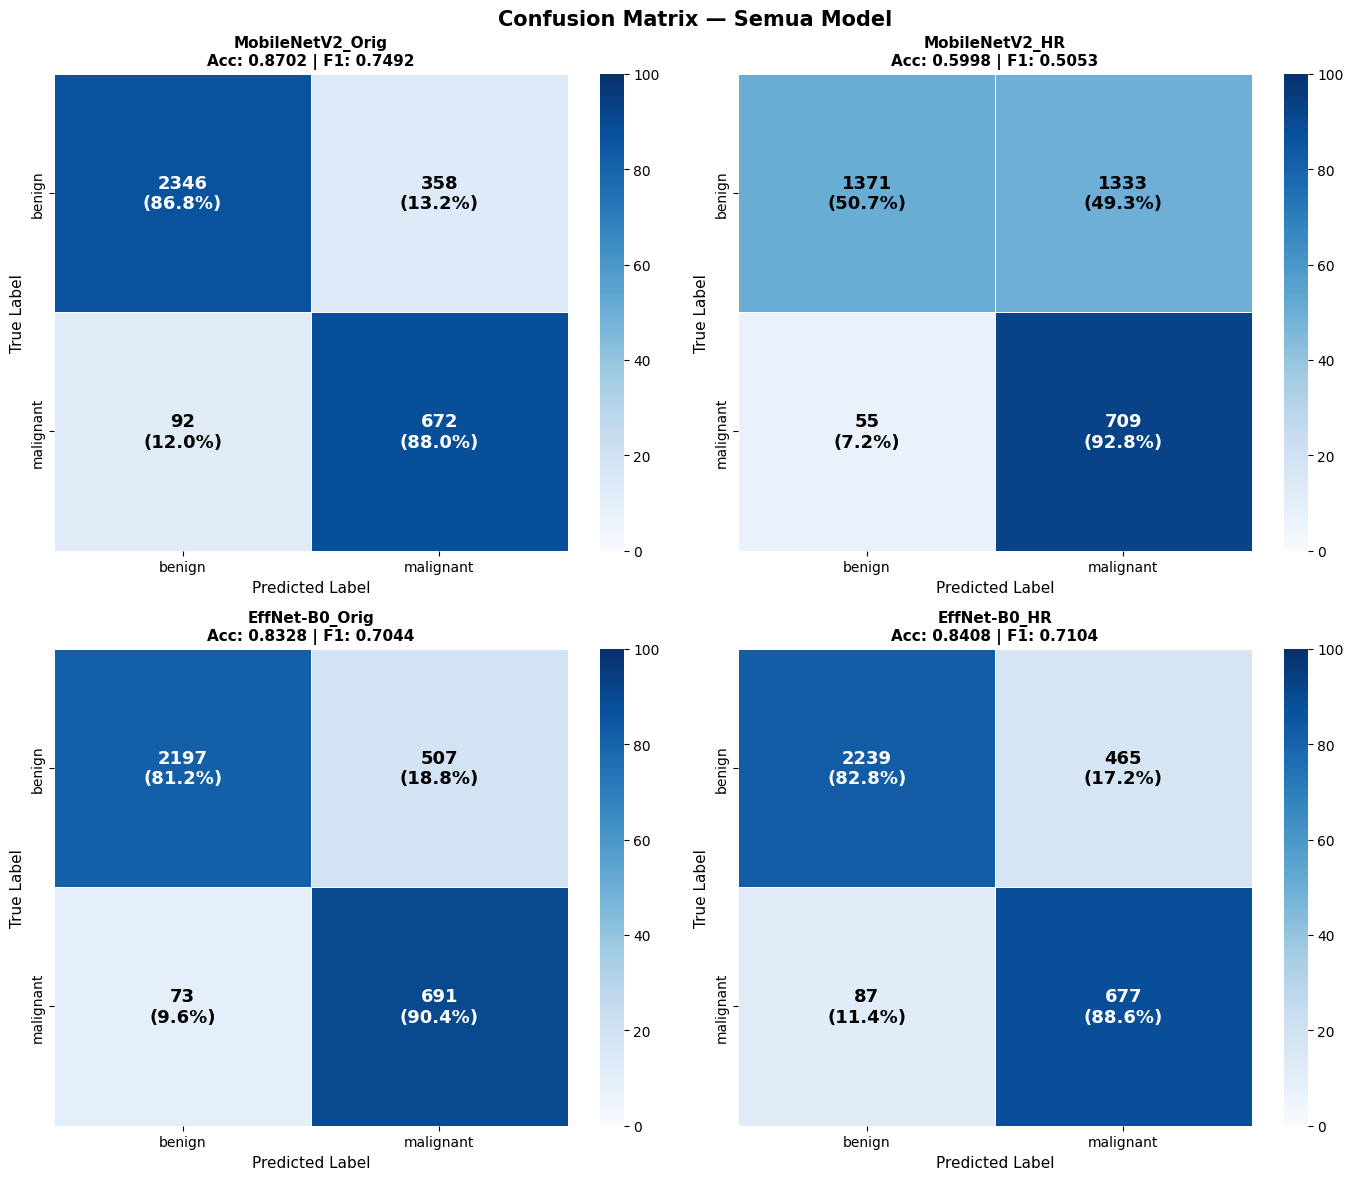


          CLASSIFICATION REPORT (TEST SET)

  ▶ MobileNetV2_Original
              precision    recall  f1-score   support

      benign     0.9623    0.8676    0.9125      2704
   malignant     0.6524    0.8796    0.7492       764

    accuracy                         0.8702      3468
   macro avg     0.8073    0.8736    0.8308      3468
weighted avg     0.8940    0.8702    0.8765      3468


  ▶ MobileNetV2_HairRemoved
              precision    recall  f1-score   support

      benign     0.9614    0.5070    0.6639      2704
   malignant     0.3472    0.9280    0.5053       764

    accuracy                         0.5998      3468
   macro avg     0.6543    0.7175    0.5846      3468
weighted avg     0.8261    0.5998    0.6290      3468


  ▶ EfficientNet-B0_Original
              precision    recall  f1-score   support

      benign     0.9678    0.8125    0.8834      2704
   malignant     0.5768    0.9045    0.7044       764

    accuracy                         0.8328      3468

In [22]:
# CONFUSION MATRIX

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle("Confusion Matrix — Semua Model", fontsize=15, fontweight="bold")
axes = axes.flatten()

for ax, (name, res) in zip(axes, results.items()):
    cm     = res["cm"]
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(
        cm_pct, annot=False, fmt=".1f", ax=ax,
        cmap="Blues", linewidths=0.5, linecolor="white",
        xticklabels=CLASSES, yticklabels=CLASSES,
        vmin=0, vmax=100
    )
    # Annotate cells manually: nilai absolut + persentase
    for i in range(2):
        for j in range(2):
            color = "white" if cm_pct[i,j] > 60 else "black"
            ax.text(j + 0.5, i + 0.5,
                    f"{cm[i,j]}\n({cm_pct[i,j]:.1f}%)",
                    ha="center", va="center",
                    fontsize=13, fontweight="bold", color=color)
    short_name = name.replace("EfficientNet-B0","EffNet-B0").replace("HairRemoved","HR").replace("Original","Orig")
    ax.set_title(f"{short_name}\nAcc: {res['accuracy']:.4f} | F1: {res['f1_score']:.4f}",
                 fontweight="bold", fontsize=11)
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Classification Report per model ───────────────────────────
print("\n" + "="*65)
print("          CLASSIFICATION REPORT (TEST SET)")
print("="*65)
for name, res in results.items():
    print(f"\n  ▶ {name}")
    print(classification_report(
        res["y_true"], res["y_pred"],
        target_names=CLASSES, digits=4
    ))

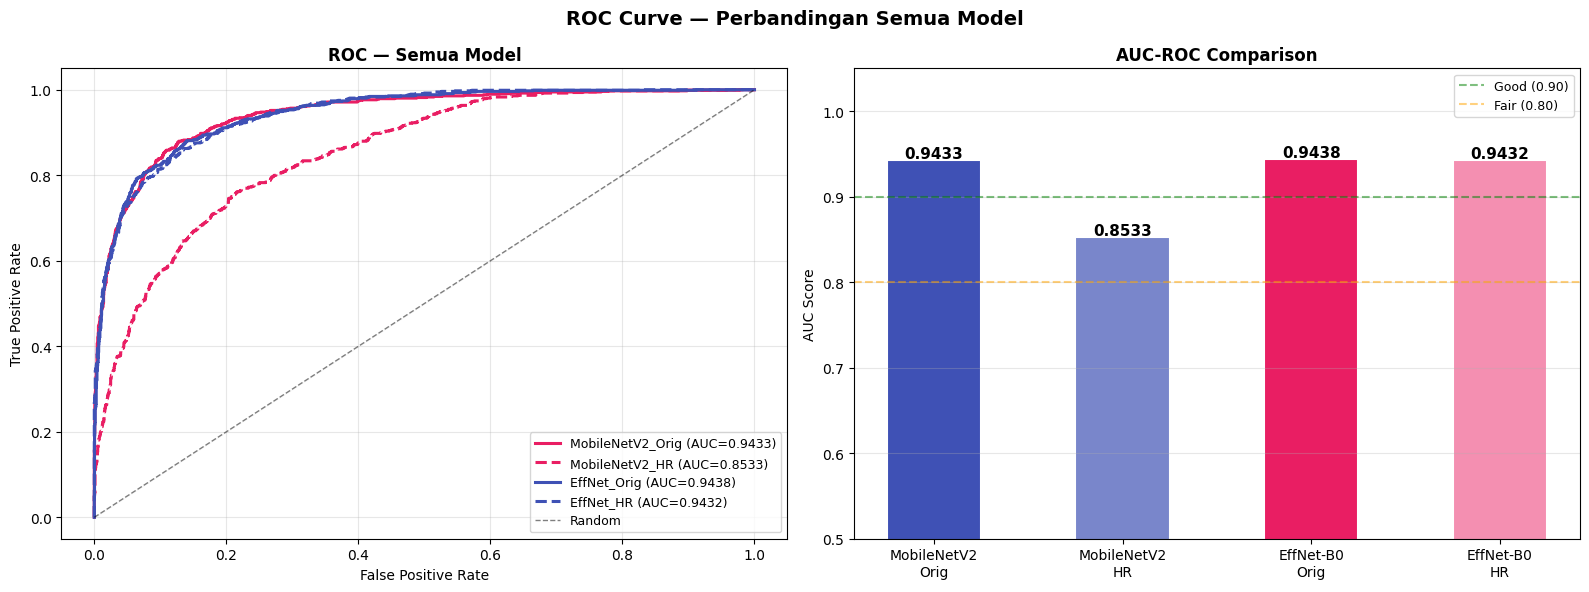

In [23]:
# ROC Curve & AUC Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("ROC Curve — Perbandingan Semua Model", fontsize=14, fontweight="bold")

color_map = {
    "EfficientNet-B0_Original"   : ("#3F51B5", "-"),
    "EfficientNet-B0_HairRemoved": ("#3F51B5", "--"),
    "MobileNetV2_Original"       : ("#E91E63", "-"),
    "MobileNetV2_HairRemoved"    : ("#E91E63", "--"),
}

ax = axes[0]
for name, res in results.items():
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_prob"])
    color, ls   = color_map[name]
    short = name.replace("EfficientNet-B0","EffNet").replace("HairRemoved","HR").replace("Original","Orig")
    ax.plot(fpr, tpr, color=color, linestyle=ls, linewidth=2.2,
            label=f"{short} (AUC={res['auc']:.4f})")
ax.plot([0,1],[0,1], "k--", linewidth=1, alpha=0.5, label="Random")
ax.fill_between([0,1],[0,1],[0,1], alpha=0.05, color="gray")
ax.set_title("ROC — Semua Model", fontweight="bold")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=9, loc="lower right"); ax.grid(alpha=0.3)

ax = axes[1]
names_short = [n.replace("EfficientNet-B0","EffNet-B0").replace("HairRemoved","HR").replace("Original","Orig").replace("_","\n")
               for n in results.keys()]
aucs        = [res["auc"] for res in results.values()]
bar_colors  = ["#3F51B5", "#7986CB", "#E91E63", "#F48FB1"]
bars = ax.bar(names_short, aucs, color=bar_colors, edgecolor="white", linewidth=1.5, width=0.5)
for bar, auc_val in zip(bars, aucs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f"{auc_val:.4f}", ha="center", fontsize=11, fontweight="bold")
ax.set_title("AUC-ROC Comparison", fontweight="bold")
ax.set_ylabel("AUC Score"); ax.set_ylim(0.5, 1.05)
ax.axhline(0.9, color="green", linestyle="--", alpha=0.5, linewidth=1.5, label="Good (0.90)")
ax.axhline(0.8, color="orange", linestyle="--", alpha=0.5, linewidth=1.5, label="Fair (0.80)")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()


           TABEL EVALUASI KOMPREHENSIF — TEST SET
                                  Dataset     Architecture  Accuracy  Precision  Recall  Specificity  F1-Score  AUC-ROC  Inf. Time (ms)  Train Time (m)  Params (M)
Model                                                                                                                                                              
MobileNetV2_Original             Original      MobileNetV2    0.8702     0.6524  0.8796       0.8676    0.7492   0.9433          26.698           145.2        2.55
MobileNetV2_HairRemoved      Hair Removed      MobileNetV2    0.5998     0.3472  0.9280       0.5070    0.5053   0.8533          32.567            43.4        2.55
EfficientNet-B0_Original         Original  EfficientNet-B0    0.8328     0.5768  0.9045       0.8125    0.7044   0.9438          19.996             0.0        4.34
EfficientNet-B0_HairRemoved  Hair Removed  EfficientNet-B0    0.8408     0.5928  0.8861       0.8280    0.7104   0.9432          

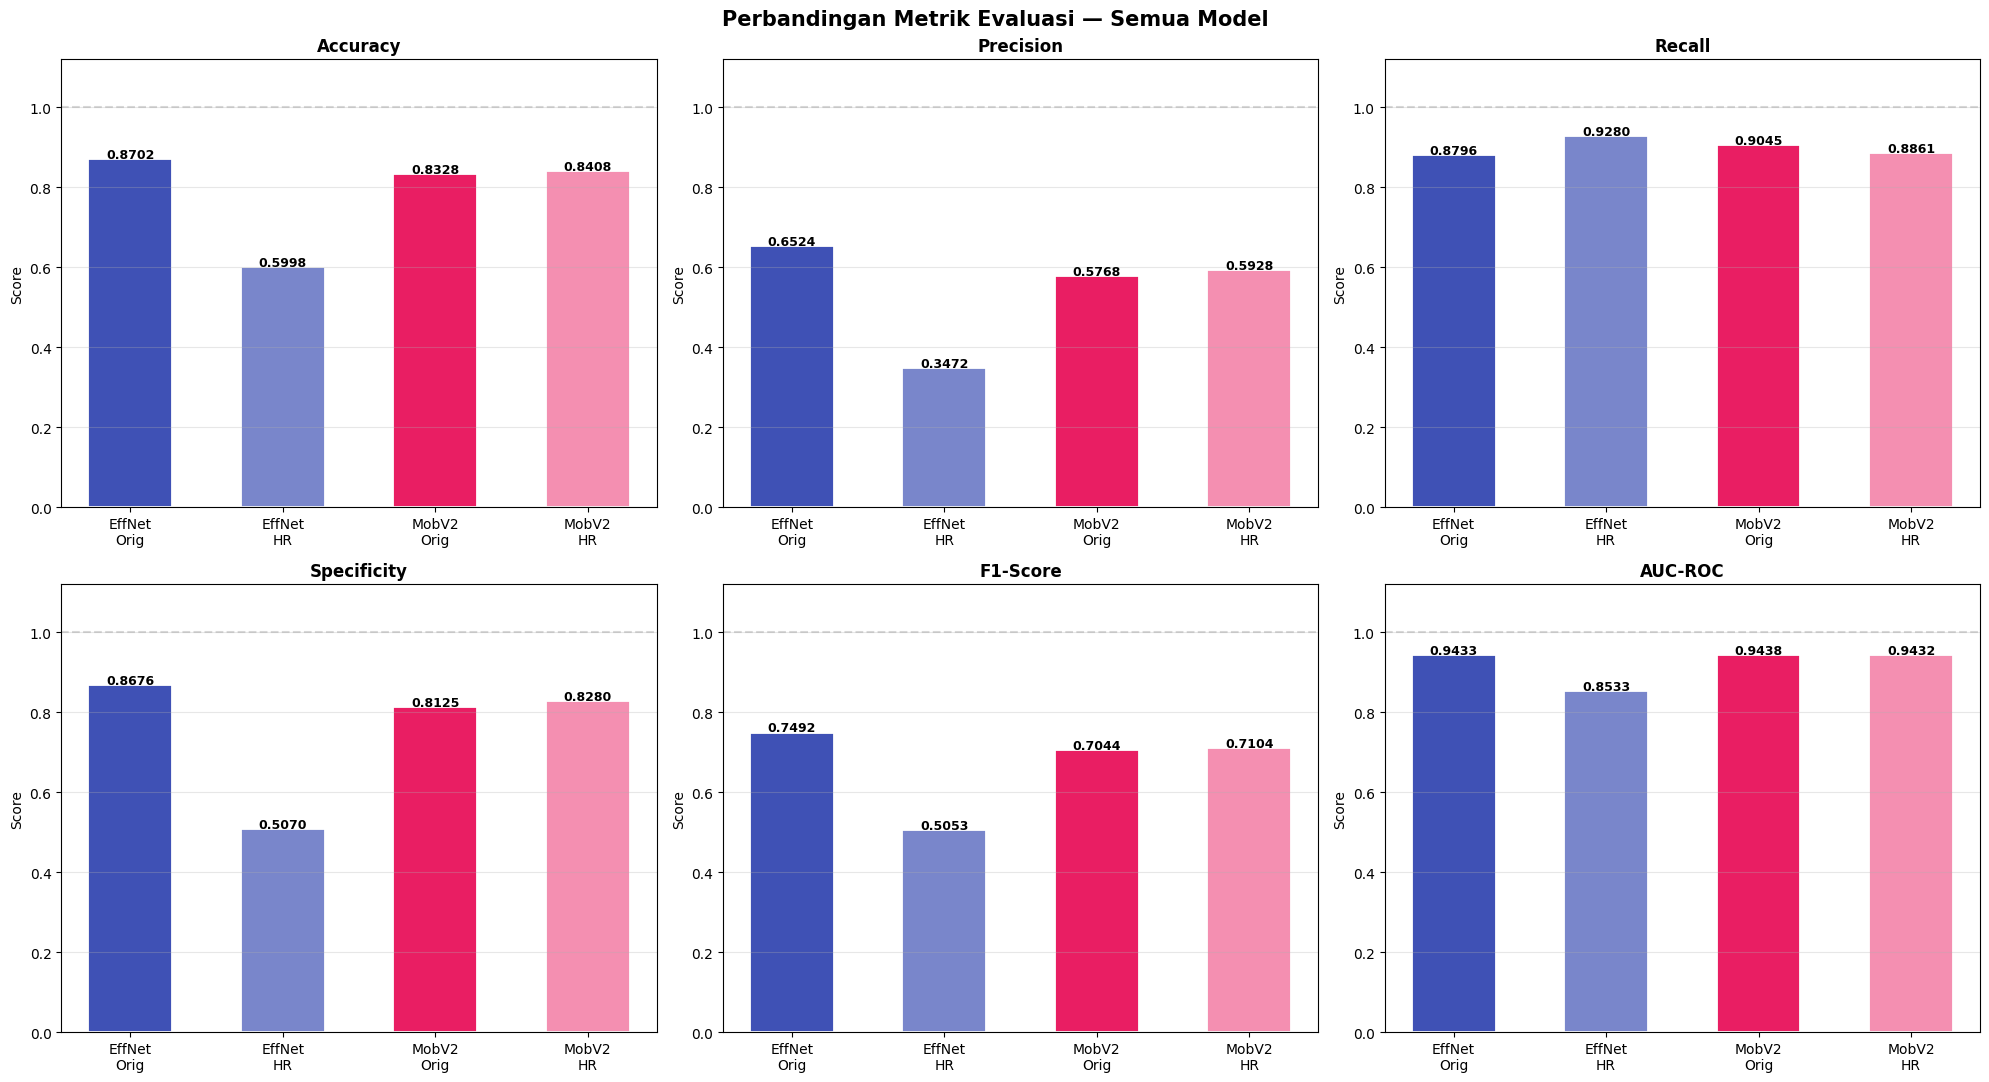

In [24]:
# Tabel Perbandingan Komprehensif

metrics_df = pd.DataFrame([
    {
        "Model"          : name,
        "Dataset"        : "Original" if "Original" in name else "Hair Removed",
        "Architecture"   : "EfficientNet-B0" if "EfficientNet" in name else "MobileNetV2",
        "Accuracy"       : round(res["accuracy"],   4),
        "Precision"      : round(res["precision"],  4),
        "Recall"         : round(res["recall"],     4),
        "Specificity"    : round(res["specificity"],4),
        "F1-Score"       : round(res["f1_score"],   4),
        "AUC-ROC"        : round(res["auc"],        4),
        "Inf. Time (ms)" : round(res["inference_per_img"], 3),
        "Train Time (m)" : round(res["training_time"] / 60, 1),
        "Params (M)"     : round(res["n_params"] / 1e6, 2),
    }
    for name, res in results.items()
]).set_index("Model")

print("\n" + "="*80)
print("           TABEL EVALUASI KOMPREHENSIF — TEST SET")
print("="*80)
print(metrics_df.to_string())
print("="*80)

metrics_df.to_csv(OUTPUT_DIR / "evaluation_results.csv")
print(f"\n✅ Tabel disimpan ke: {OUTPUT_DIR / 'evaluation_results.csv'}")

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
fig.suptitle("Perbandingan Metrik Evaluasi — Semua Model", fontsize=15, fontweight="bold")
axes = axes.flatten()

metric_cols = ["Accuracy", "Precision", "Recall", "Specificity", "F1-Score", "AUC-ROC"]
bar_colors  = ["#3F51B5", "#7986CB", "#E91E63", "#F48FB1"]
short_labels = ["EffNet\nOrig", "EffNet\nHR", "MobV2\nOrig", "MobV2\nHR"]

for ax, metric in zip(axes, metric_cols):
    vals = metrics_df[metric].values
    bars = ax.bar(short_labels, vals, color=bar_colors, edgecolor="white", linewidth=1.3, width=0.55)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")
    ax.set_title(metric, fontweight="bold", fontsize=12)
    ax.set_ylabel("Score"); ax.set_ylim(0, 1.12)
    ax.axhline(1.0, color="gray", linestyle="--", alpha=0.3)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

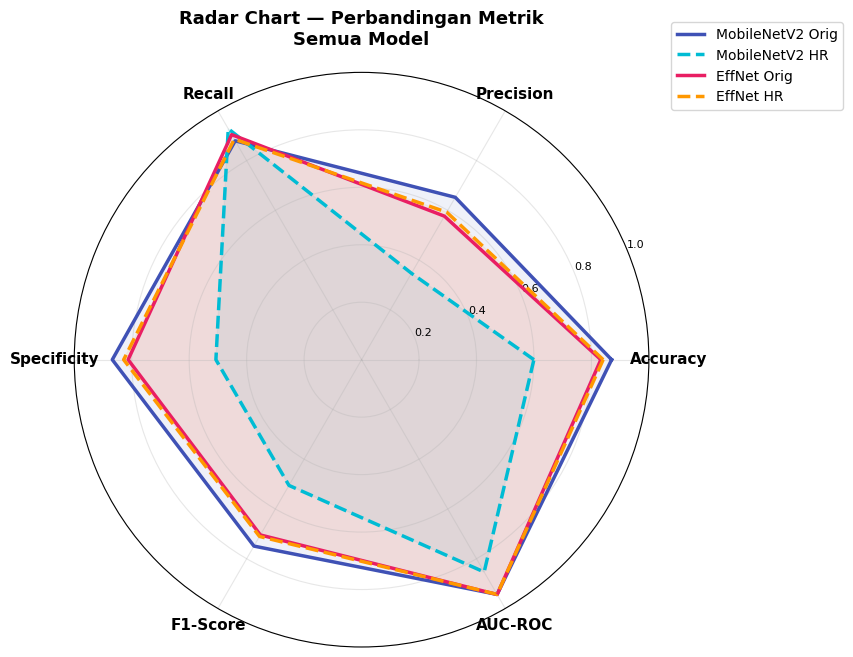

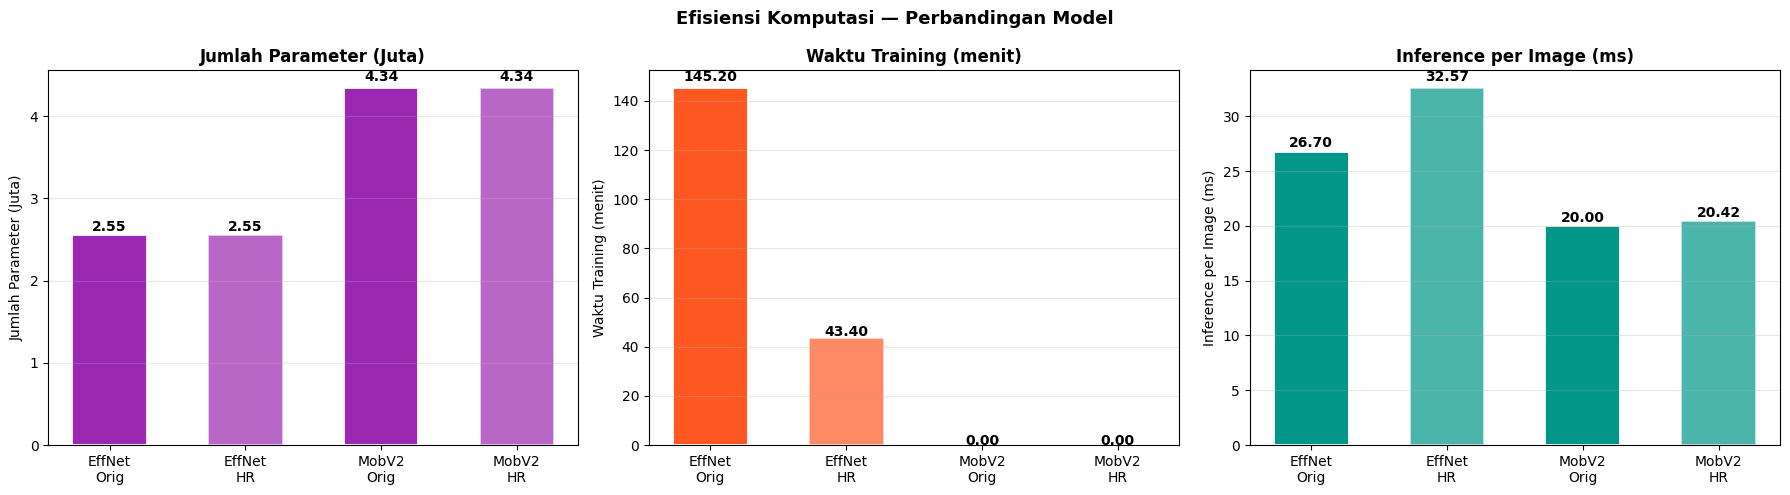

In [26]:
# Radar Chart + Analisis Efisiensi Komputasi

radar_metrics = ["Accuracy", "Precision", "Recall", "Specificity", "F1-Score", "AUC-ROC"]
n_metrics     = len(radar_metrics)
angles        = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
angles       += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
radar_colors = ["#3F51B5", "#00BCD4", "#E91E63", "#FF9800"]
linestyles   = ["-", "--", "-", "--"]

for (name, res), color, ls in zip(results.items(), radar_colors, linestyles):
    values = [
        res["accuracy"], res["precision"], res["recall"],
        res["specificity"], res["f1_score"], res["auc"]
    ]
    values += values[:1]
    short  = (name.replace("EfficientNet-B0","EffNet")
                  .replace("HairRemoved","HR")
                  .replace("Original","Orig")
                  .replace("_"," "))
    ax.plot(angles, values, color=color, linestyle=ls, linewidth=2.5, label=short)
    ax.fill(angles, values, color=color, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_metrics, fontsize=11, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2","0.4","0.6","0.8","1.0"], fontsize=8)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=10)
ax.set_title("Radar Chart — Perbandingan Metrik\nSemua Model",
             fontsize=13, fontweight="bold", pad=20)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "radar_chart.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Efisiensi Komputasi — Perbandingan Model", fontsize=13, fontweight="bold")

short_labels = ["EffNet\nOrig", "EffNet\nHR", "MobV2\nOrig", "MobV2\nHR"]
bar_colors   = ["#3F51B5", "#7986CB", "#E91E63", "#F48FB1"]

alphas = [1.0, 0.7, 1.0, 0.7]

metrics_eff = [
    ("Params (M)",     "Jumlah Parameter (Juta)", "#9C27B0"),
    ("Train Time (m)", "Waktu Training (menit)",   "#FF5722"),
    ("Inf. Time (ms)", "Inference per Image (ms)", "#009688"),
]

for ax, (col, ylabel, color) in zip(axes, metrics_eff):
    vals = metrics_df[col].values

    bars = []
    for i, (label, val, alpha) in enumerate(zip(short_labels, vals, alphas)):
        bar = ax.bar(i, val, color=color, alpha=alpha,
                     edgecolor="white", linewidth=1.3, width=0.55)
        bars.append(bar[0])

    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() * 1.02,
                f"{v:.2f}", ha="center", fontsize=10, fontweight="bold")

    ax.set_title(ylabel, fontweight="bold")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(short_labels)))
    ax.set_xticklabels(short_labels)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "computational_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()


    ANALISIS DAMPAK DIGITAL HAIR REMOVAL

  📌 EfficientNet-B0
  Metrik            Original   Hair Rem      Delta       Dampak
  ---------------------------------------------------------
  Accuracy            0.8328     0.8408    +0.0080  ✅ +0.0080
  Precision           0.5768     0.5928    +0.0160  ✅ +0.0160
  Recall              0.9045     0.8861    -0.0184  ❌ 0.0184
  Specificity         0.8125     0.8280    +0.0155  ✅ +0.0155
  F1-Score            0.7044     0.7104    +0.0060  ✅ +0.0060
  AUC-ROC             0.9438     0.9432    -0.0006  ➡️ ~0.0006

  📌 MobileNetV2
  Metrik            Original   Hair Rem      Delta       Dampak
  ---------------------------------------------------------
  Accuracy            0.8702     0.5998    -0.2704  ❌ 0.2704
  Precision           0.6524     0.3472    -0.3052  ❌ 0.3052
  Recall              0.8796     0.9280    +0.0484  ✅ +0.0484
  Specificity         0.8676     0.5070    -0.3606  ❌ 0.3606
  F1-Score            0.7492     0.5053    -0.2439  ❌ 0

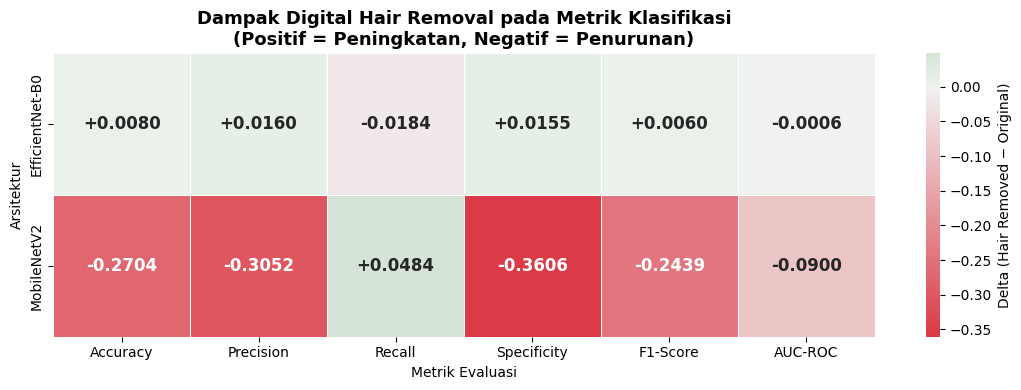

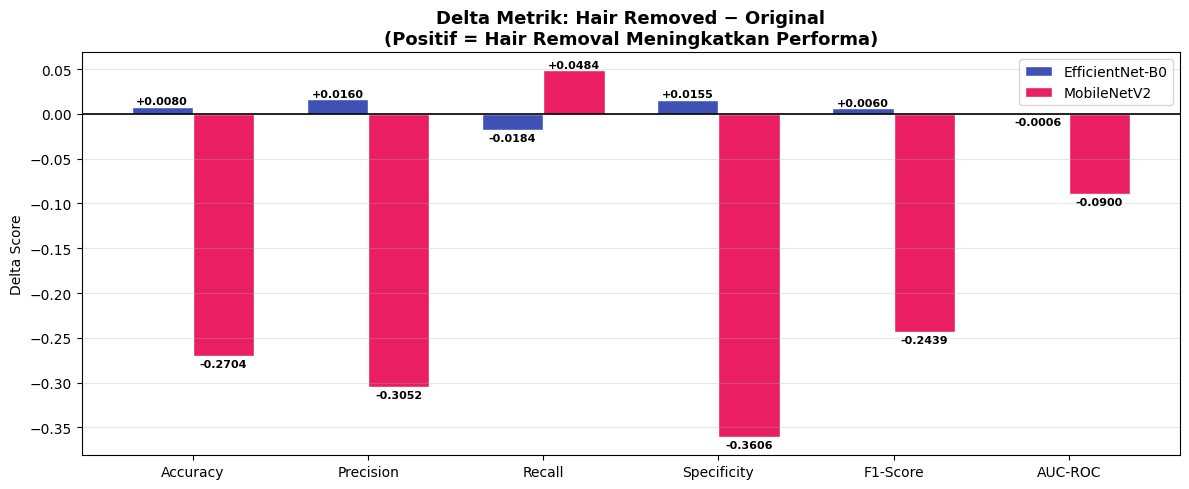

In [27]:
# Analisis Dampak Digital Hair Removal

print("\n" + "="*65)
print("    ANALISIS DAMPAK DIGITAL HAIR REMOVAL")
print("="*65)

analysis_metrics = ["Accuracy","Precision","Recall","Specificity","F1-Score","AUC-ROC"]

for arch in ["EfficientNet-B0", "MobileNetV2"]:
    orig_key = f"{arch}_Original"
    hair_key = f"{arch}_HairRemoved"

    print(f"\n  📌 {arch}")
    print(f"  {'Metrik':<15} {'Original':>10} {'Hair Rem':>10} {'Delta':>10} {'Dampak':>12}")
    print("  " + "-"*57)

    for m in analysis_metrics:
        v_orig = metrics_df.loc[orig_key, m]
        v_hair = metrics_df.loc[hair_key, m]
        delta  = v_hair - v_orig
        icon   = "✅ +" if delta > 0.001 else ("❌ " if delta < -0.001 else "➡️ ~")
        print(f"  {m:<15} {v_orig:>10.4f} {v_hair:>10.4f} {delta:>+10.4f}  {icon}{abs(delta):.4f}")

delta_data = {}
for arch in ["EfficientNet-B0", "MobileNetV2"]:
    orig_key = f"{arch}_Original"
    hair_key = f"{arch}_HairRemoved"
    delta_data[arch] = {
        m: metrics_df.loc[hair_key, m] - metrics_df.loc[orig_key, m]
        for m in analysis_metrics
    }

delta_df = pd.DataFrame(delta_data).T

fig, ax = plt.subplots(figsize=(11, 4))
cmap    = sns.diverging_palette(10, 130, as_cmap=True)
sns.heatmap(
    delta_df, annot=True, fmt="+.4f", cmap=cmap,
    center=0, linewidths=0.5, linecolor="white",
    ax=ax, cbar_kws={"label": "Delta (Hair Removed − Original)"},
    annot_kws={"size": 12, "weight": "bold"}
)
ax.set_title("Dampak Digital Hair Removal pada Metrik Klasifikasi\n(Positif = Peningkatan, Negatif = Penurunan)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Metrik Evaluasi"); ax.set_ylabel("Arsitektur")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hair_removal_impact_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
x      = np.arange(len(analysis_metrics))
w      = 0.35
b1 = ax.bar(x - w/2, delta_df.loc["EfficientNet-B0"].values, w,
            label="EfficientNet-B0", color="#3F51B5", edgecolor="white")
b2 = ax.bar(x + w/2, delta_df.loc["MobileNetV2"].values,     w,
            label="MobileNetV2",     color="#E91E63", edgecolor="white")

ax.axhline(0, color="black", linewidth=1.2)
for bar in list(b1) + list(b2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2,
            h + (0.001 if h >= 0 else -0.003),
            f"{h:+.4f}", ha="center", fontsize=8, fontweight="bold",
            va="bottom" if h >= 0 else "top")

ax.set_title("Delta Metrik: Hair Removed − Original\n(Positif = Hair Removal Meningkatkan Performa)",
             fontsize=13, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(analysis_metrics); ax.set_ylabel("Delta Score")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "hair_removal_delta_bar.png", dpi=150, bbox_inches="tight")
plt.show()

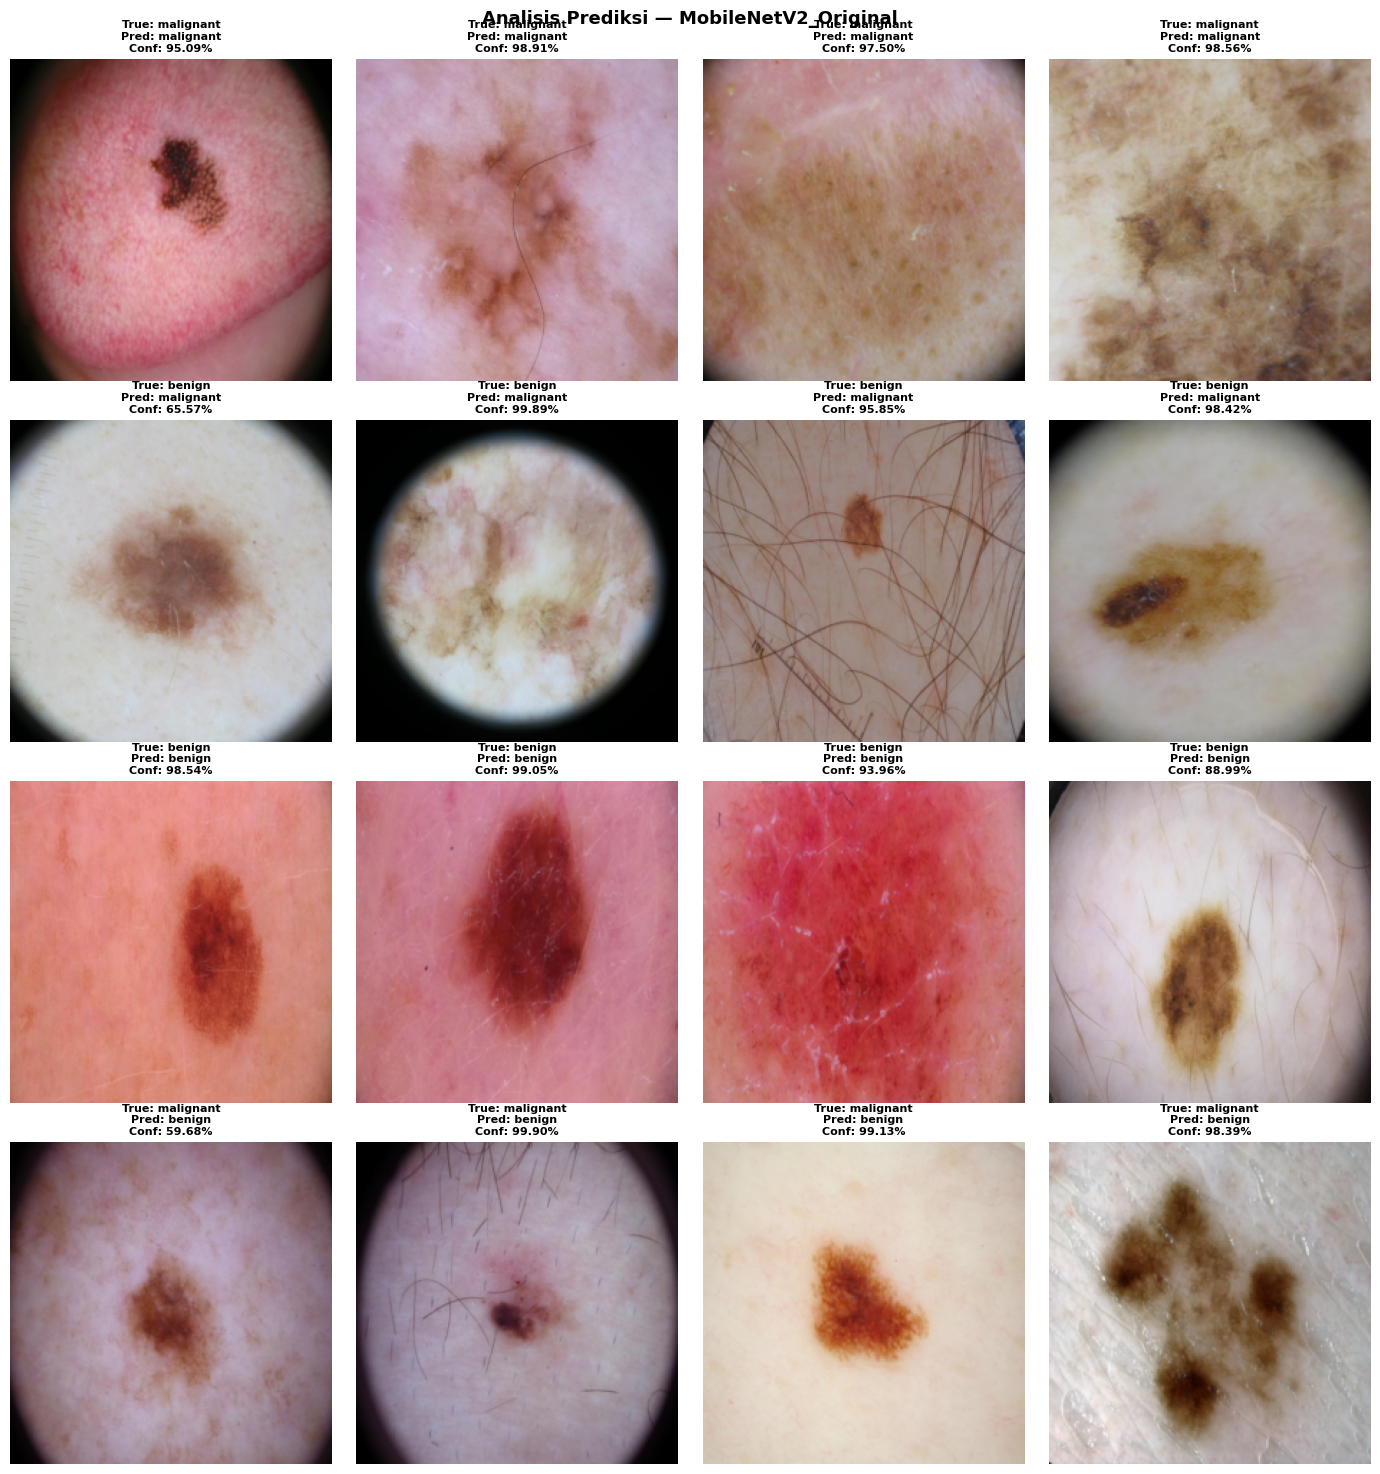

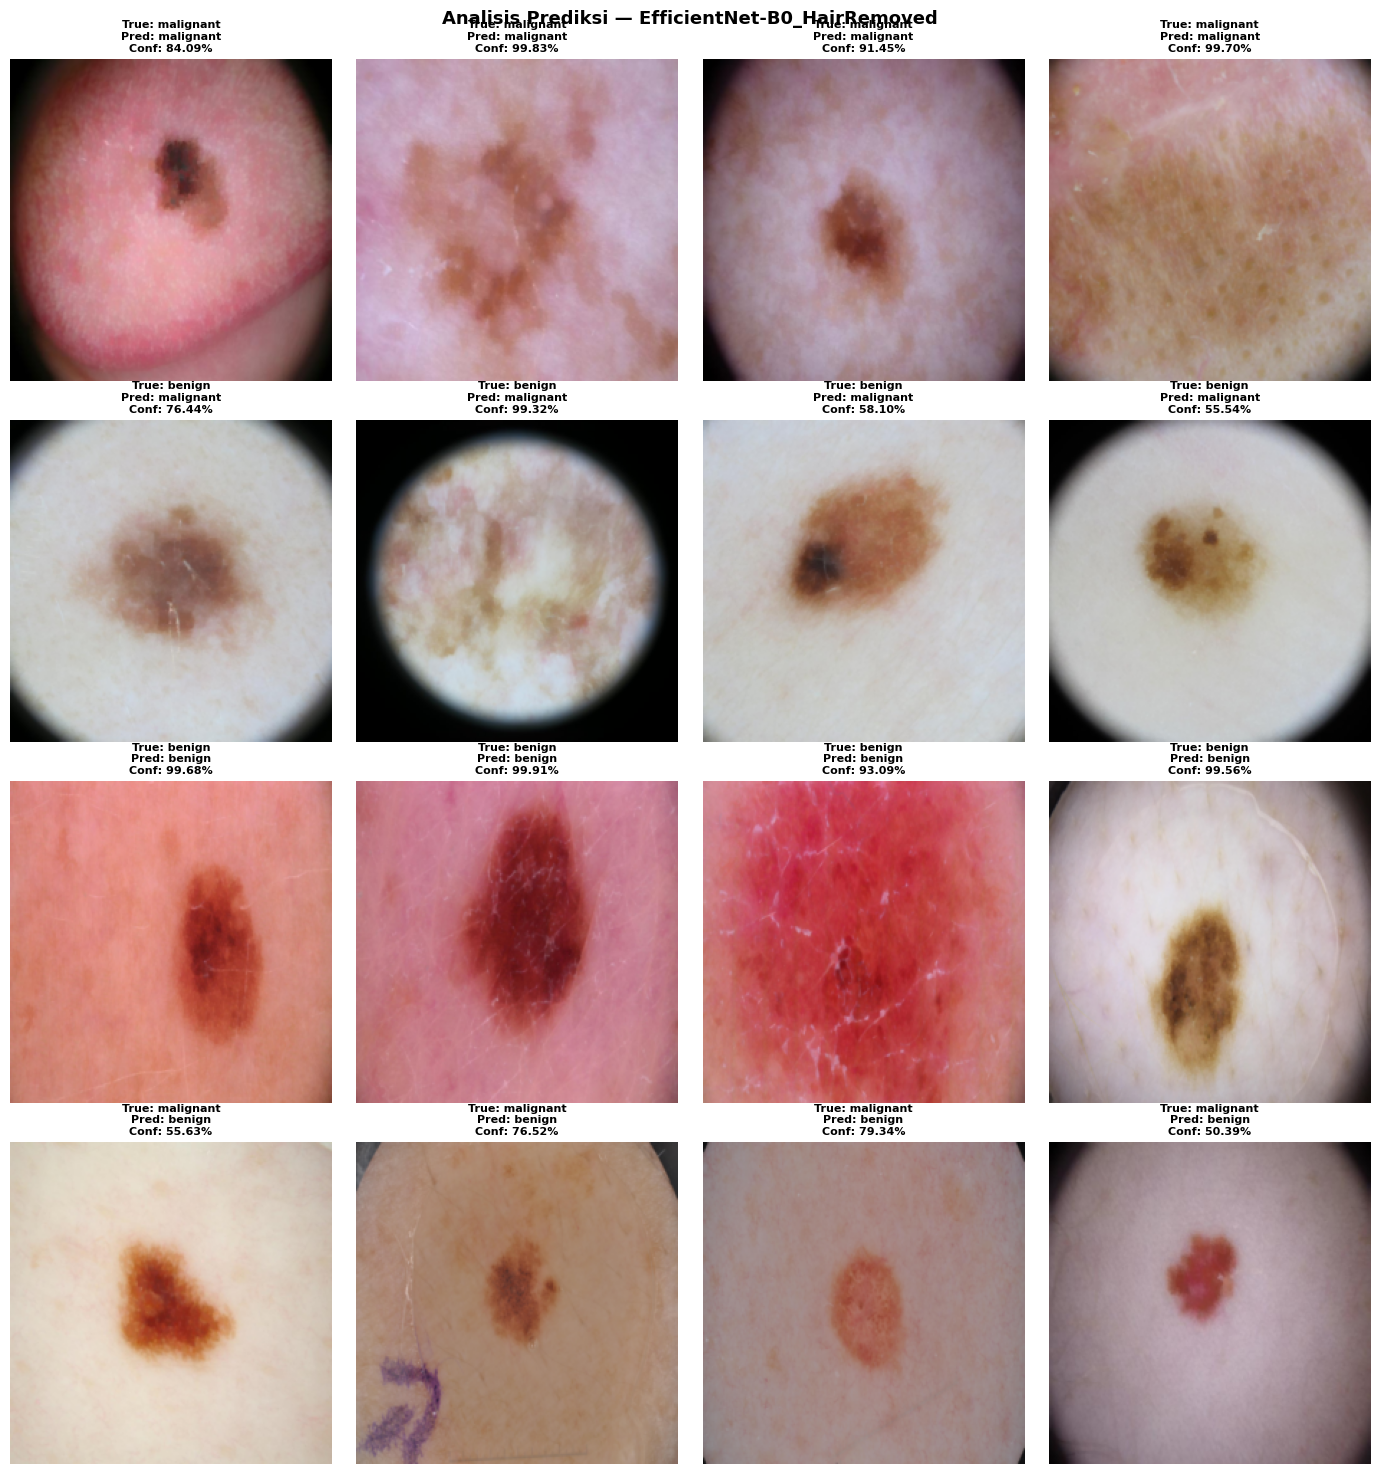

In [28]:
# Visualisasi Prediksi, True/False Positive/Negative

def visualize_predictions(model, test_loader, model_name, n_show=4, device=DEVICE):
    model.eval()
    tp_imgs, fp_imgs, tn_imgs, fn_imgs = [], [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs= model(images)
            probs  = F.softmax(outputs, dim=1)
            preds  = outputs.argmax(dim=1).cpu()
            labels_cpu = labels.cpu()

            for img, true, pred, prob in zip(images.cpu(), labels_cpu, preds, probs.cpu()):
                confidence = prob[pred].item()
                entry = (img, true.item(), pred.item(), confidence)
                if true == 1 and pred == 1 and len(tp_imgs) < n_show: tp_imgs.append(entry)
                elif true == 0 and pred == 1 and len(fp_imgs) < n_show: fp_imgs.append(entry)
                elif true == 0 and pred == 0 and len(tn_imgs) < n_show: tn_imgs.append(entry)
                elif true == 1 and pred == 0 and len(fn_imgs) < n_show: fn_imgs.append(entry)

    categories = [
        ("True Positive (TP)",  tp_imgs, "#4CAF50"),
        ("False Positive (FP)", fp_imgs, "#FF9800"),
        ("True Negative (TN)",  tn_imgs, "#2196F3"),
        ("False Negative (FN)", fn_imgs, "#F44336"),
    ]

    fig, axes = plt.subplots(4, n_show, figsize=(n_show * 3.5, 15))
    fig.suptitle(f"Analisis Prediksi — {model_name}", fontsize=13, fontweight="bold")

    mean_t = torch.tensor(MEAN).view(3,1,1)
    std_t  = torch.tensor(STD) .view(3,1,1)

    for row, (cat_name, entries, border_color) in enumerate(categories):
        for col in range(n_show):
            ax = axes[row, col]
            if col < len(entries):
                img, true, pred, conf = entries[col]
                img_display = (img * std_t + mean_t).permute(1,2,0).numpy().clip(0,1)
                ax.imshow(img_display)
                ax.set_title(
                    f"True: {IDX2CLASS[true]}\nPred: {IDX2CLASS[pred]}\nConf: {conf:.2%}",
                    fontsize=8, fontweight="bold"
                )
                for spine in ax.spines.values():
                    spine.set_edgecolor(border_color)
                    spine.set_linewidth(3)
                    spine.set_visible(True)
            else:
                ax.text(0.5, 0.5, "N/A", ha="center", va="center", fontsize=12)
            ax.axis("off")
            if col == 0:
                ax.set_ylabel(cat_name, fontsize=10, fontweight="bold",
                              rotation=90, labelpad=10, visible=True)

    plt.tight_layout()
    safe_name = model_name.replace("/","_").replace(" ","_")
    plt.savefig(OUTPUT_DIR / f"predictions_{safe_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


best_models = sorted(results.items(), key=lambda x: x[1]["f1_score"], reverse=True)[:2]
for name, _ in best_models:
    test_loader = test_loaders_map[name]
    visualize_predictions(trained_models[name], test_loader, name)


              RINGKASAN HASIL EVALUASI FINAL

  🏆 Model Terbaik (F1-Score): MobileNetV2_Original
     Accuracy   : 0.8702  (87.02%)
     Precision  : 0.6524
     Recall     : 0.8796
     Specificity: 0.8676
     F1-Score   : 0.7492
     AUC-ROC    : 0.9433

----------------------------------------------------------------------
  📊 TABEL RANGKUMAN (diurutkan berdasarkan F1-Score)
----------------------------------------------------------------------
                             Accuracy  Precision  Recall  F1-Score  AUC-ROC  Inf. Time (ms)  Params (M)
Model                                                                                                  
MobileNetV2_Original           0.8702     0.6524  0.8796    0.7492   0.9433          26.698        2.55
EfficientNet-B0_HairRemoved    0.8408     0.5928  0.8861    0.7104   0.9432          20.417        4.34
EfficientNet-B0_Original       0.8328     0.5768  0.9045    0.7044   0.9438          19.996        4.34
MobileNetV2_HairRemoved   

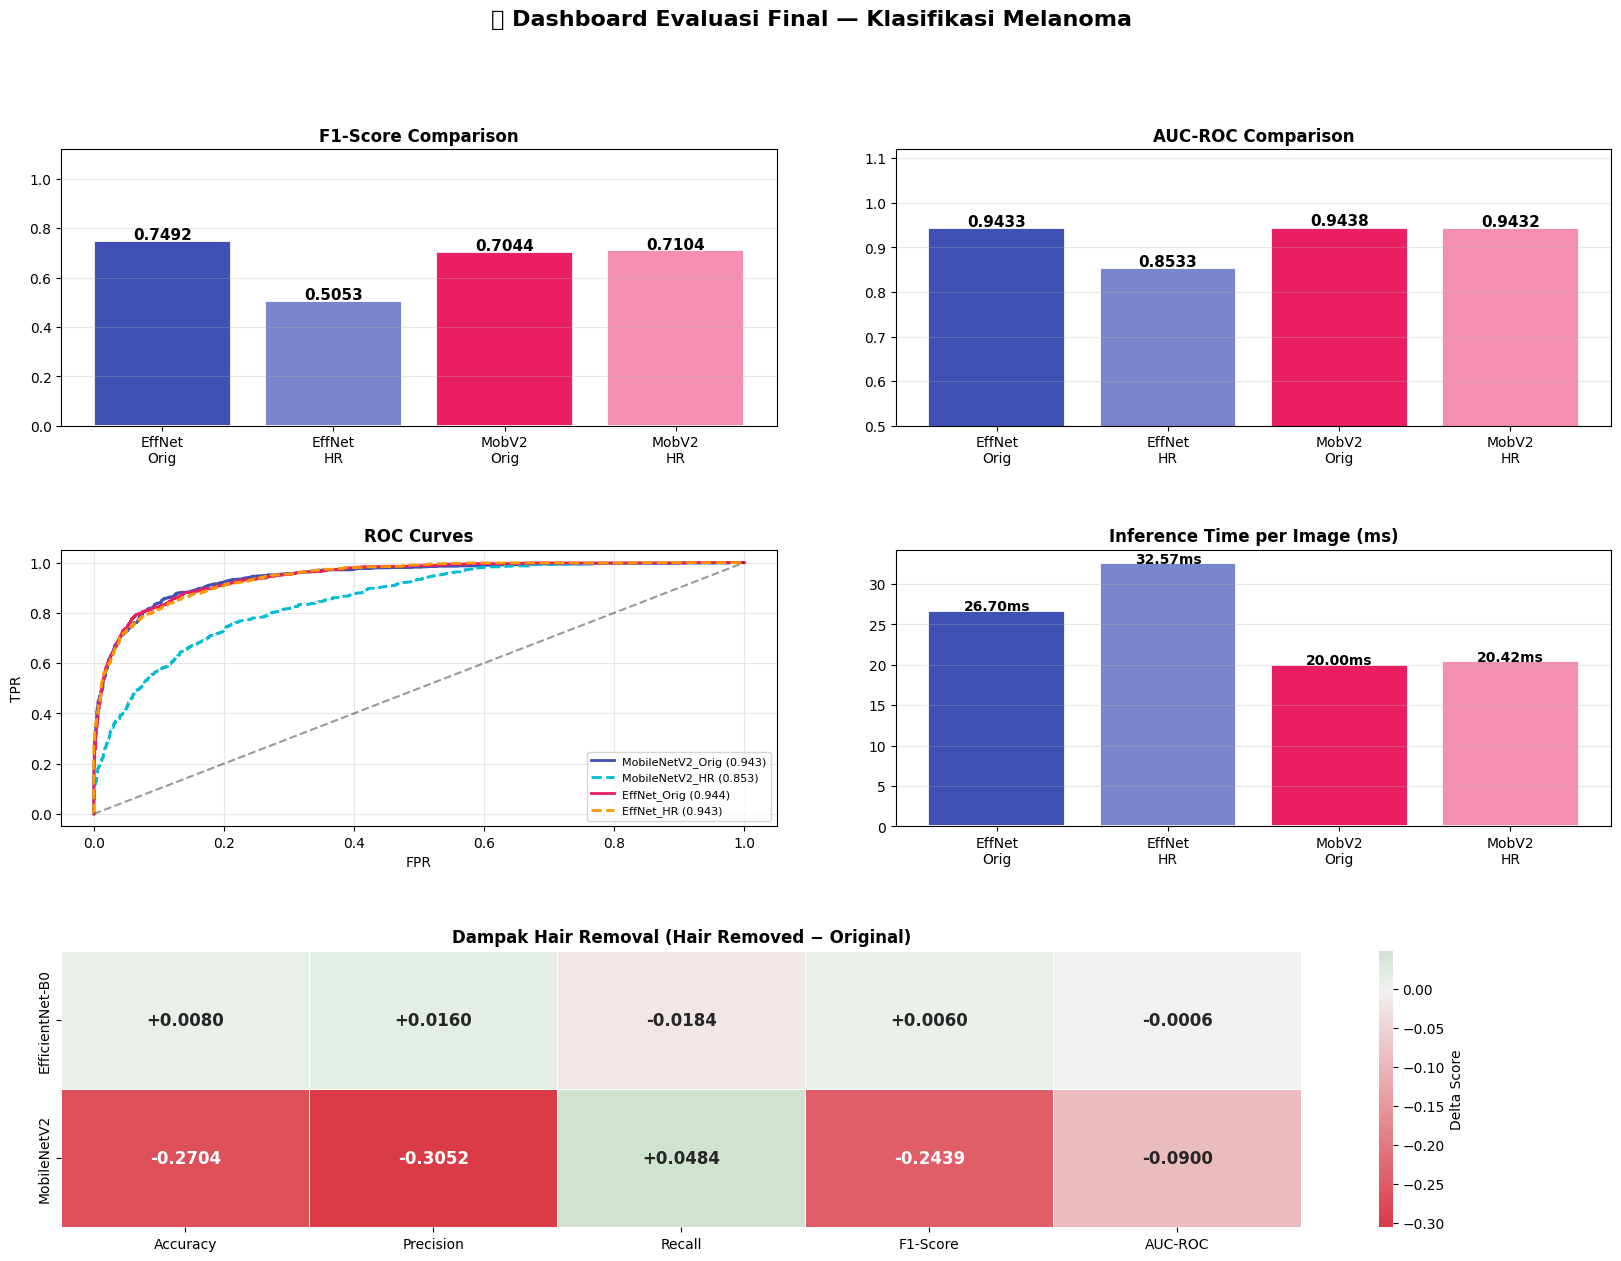


  📝 KESIMPULAN ANALISIS

  [EfficientNet-B0]
    Hair Removal MENINGKAT F1-Score sebesar 0.0060 (0.60%)
    Original: 0.7044 → Hair Removed: 0.7104

  [MobileNetV2]
    Hair Removal MENURUN F1-Score sebesar 0.2439 (24.39%)
    Original: 0.7492 → Hair Removed: 0.5053

  🏅 Arsitektur Terbaik Secara Keseluruhan: MobileNetV2
  🏆 Konfigurasi Terbaik: MobileNetV2_Original

  Output tersimpan di: /kaggle/working/outputs

  📁 Files output yang dihasilkan:
     augmentation_sample.png                       (821.9 KB)
     computational_efficiency.png                  (83.9 KB)
     confusion_matrix.png                          (173.9 KB)
     eda_dimensions.png                            (47.7 KB)
     eda_distribution.png                          (104.9 KB)
     evaluation_results.csv                        (0.5 KB)
     final_dashboard.png                           (229.7 KB)
     hair_removal_delta_bar.png                    (74.4 KB)
     hair_removal_impact_heatmap.png               (87.8

In [29]:
# KESIMPULAN

print("\n" + "="*70)
print("              RINGKASAN HASIL EVALUASI FINAL")
print("="*70)

best_name = max(results, key=lambda k: results[k]["f1_score"])
best_res  = results[best_name]

print(f"\n  🏆 Model Terbaik (F1-Score): {best_name}")
print(f"     Accuracy   : {best_res['accuracy']:.4f}  ({best_res['accuracy']*100:.2f}%)")
print(f"     Precision  : {best_res['precision']:.4f}")
print(f"     Recall     : {best_res['recall']:.4f}")
print(f"     Specificity: {best_res['specificity']:.4f}")
print(f"     F1-Score   : {best_res['f1_score']:.4f}")
print(f"     AUC-ROC    : {best_res['auc']:.4f}")

print("\n" + "-"*70)
print("  📊 TABEL RANGKUMAN (diurutkan berdasarkan F1-Score)")
print("-"*70)
summary = metrics_df[["Accuracy","Precision","Recall","F1-Score","AUC-ROC","Inf. Time (ms)","Params (M)"]]\
    .sort_values("F1-Score", ascending=False)
print(summary.to_string())

fig = plt.figure(figsize=(20, 14))
fig.suptitle("🔬 Dashboard Evaluasi Final — Klasifikasi Melanoma",
             fontsize=16, fontweight="bold", y=0.98)

gs  = fig.add_gridspec(3, 4, hspace=0.45, wspace=0.4)

ax1 = fig.add_subplot(gs[0, :2])
f1s  = [res["f1_score"] for res in results.values()]
bars = ax1.bar(short_labels, f1s, color=bar_colors, edgecolor="white", linewidth=1.3)
for bar, v in zip(bars, f1s):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{v:.4f}", ha="center", fontsize=11, fontweight="bold")
ax1.set_title("F1-Score Comparison", fontweight="bold"); ax1.set_ylim(0, 1.12)
ax1.grid(axis="y", alpha=0.3)

ax2 = fig.add_subplot(gs[0, 2:])
auc_vals = [res["auc"] for res in results.values()]
bars = ax2.bar(short_labels, auc_vals, color=bar_colors, edgecolor="white", linewidth=1.3)
for bar, v in zip(bars, auc_vals):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f"{v:.4f}", ha="center", fontsize=11, fontweight="bold")
ax2.set_title("AUC-ROC Comparison", fontweight="bold"); ax2.set_ylim(0.5, 1.12)
ax2.grid(axis="y", alpha=0.3)

ax3 = fig.add_subplot(gs[1, :2])
for (name, res), color, ls in zip(results.items(), radar_colors, linestyles):
    fpr, tpr, _ = roc_curve(res["y_true"], res["y_prob"])
    short = name.replace("EfficientNet-B0","EffNet").replace("HairRemoved","HR").replace("Original","Orig")
    ax3.plot(fpr, tpr, color=color, linestyle=ls, linewidth=2,
             label=f"{short} ({res['auc']:.3f})")
ax3.plot([0,1],[0,1],"k--",alpha=0.4); ax3.legend(fontsize=8, loc="lower right")
ax3.set_title("ROC Curves", fontweight="bold"); ax3.grid(alpha=0.3)
ax3.set_xlabel("FPR"); ax3.set_ylabel("TPR")

ax4 = fig.add_subplot(gs[1, 2:])
inf_times = [res["inference_per_img"] for res in results.values()]
bars = ax4.bar(short_labels, inf_times, color=bar_colors, edgecolor="white", linewidth=1.3)
for bar, v in zip(bars, inf_times):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{v:.2f}ms", ha="center", fontsize=10, fontweight="bold")
ax4.set_title("Inference Time per Image (ms)", fontweight="bold")
ax4.grid(axis="y", alpha=0.3)

ax5 = fig.add_subplot(gs[2, :])
mini_metrics = ["Accuracy","Precision","Recall","F1-Score","AUC-ROC"]
delta_mini   = delta_df[mini_metrics]
cmap = sns.diverging_palette(10, 130, as_cmap=True)
sns.heatmap(delta_mini, annot=True, fmt="+.4f", cmap=cmap, center=0,
            ax=ax5, linewidths=0.5, linecolor="white",
            annot_kws={"size": 12, "weight": "bold"},
            cbar_kws={"label": "Delta Score"})
ax5.set_title("Dampak Hair Removal (Hair Removed − Original)",
              fontweight="bold", fontsize=12)

plt.savefig(OUTPUT_DIR / "final_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n" + "="*70)
print("  📝 KESIMPULAN ANALISIS")
print("="*70)

for arch in ["EfficientNet-B0", "MobileNetV2"]:
    orig_f1  = metrics_df.loc[f"{arch}_Original",    "F1-Score"]
    hair_f1  = metrics_df.loc[f"{arch}_HairRemoved", "F1-Score"]
    delta    = hair_f1 - orig_f1
    direction = "MENINGKAT" if delta > 0 else "MENURUN"
    print(f"\n  [{arch}]")
    print(f"    Hair Removal {direction} F1-Score sebesar {abs(delta):.4f} ({abs(delta)*100:.2f}%)")
    print(f"    Original: {orig_f1:.4f} → Hair Removed: {hair_f1:.4f}")

best_arch = max(
    ["EfficientNet-B0", "MobileNetV2"],
    key=lambda a: max(
        metrics_df.loc[f"{a}_Original","F1-Score"],
        metrics_df.loc[f"{a}_HairRemoved","F1-Score"]
    )
)
print(f"\n  🏅 Arsitektur Terbaik Secara Keseluruhan: {best_arch}")
print(f"  🏆 Konfigurasi Terbaik: {best_name}")
print(f"\n  Output tersimpan di: {OUTPUT_DIR}")

print("\n  📁 Files output yang dihasilkan:")
for f in sorted(OUTPUT_DIR.iterdir()):
    size = f.stat().st_size / 1024
    print(f"     {f.name:<45} ({size:.1f} KB)")

In [30]:
import shutil

shutil.make_archive('zipped output', 'zip', '/kaggle/working/outputs')

'/kaggle/working/zipped ouput.zip'

In [35]:
from IPython.display import FileLink
FileLink(r'zipped output.zip')

/kaggle/working/zipped ouput.zip